# Etapa 2 · Exploración descriptiva orientada al objetivo (puntos 4 y 5)

**Objetivo de indagación.** Determinar en qué medida la cobertura vegetal alrededor de las estaciones de monitoreo del SIMA se relaciona con las concentraciones de PM10, PM2.5 y NO2 en el Área Metropolitana de Monterrey (2024–2025), considerando la meteorología como control.

**Cómo está organizado este notebook**

| Sección | Qué responde |
|---|---|
| 0. Preparación | Carga de las 4 bases, unión en una sola base analítica y selección de variables |
| 1. Calidad de los datos | Faltantes, estaciones/variables problemáticas y decisiones de depuración |
| 2. Comportamiento de las variables principales (4.1) | Distribución, variabilidad y atípicos de contaminantes, NDVI y cobertura |
| 3. Comparación entre estaciones (4.2) | ¿Cuánto cambian los contaminantes y el entorno verde de una estación a otra? |
| 4. Comparación entre periodos y temporadas (4.3) | Estacionalidad, 2024 vs 2025, tipo de día y hora |
| 5. Relaciones entre variables (4.4) | Cobertura/NDVI vs contaminantes, meteorología, colinealidad |
| 6. Síntesis (punto 5) | Hallazgos, limitaciones y ruta del análisis |

**Reproducibilidad.** Coloca este notebook junto a la carpeta `datos/` (las cuatro bases CSV) y ejecútalo de arriba a abajo. Las figuras se guardan en `figuras/` y las tablas en `tablas/`.

## 0. Preparación

In [2]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

DATOS, FIG, TAB = Path("datos"), Path("figuras"), Path("tablas")
FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

CONT   = ["PM10", "PM2.5", "NO2"]                       # variables respuesta
UNID   = {"PM10": "µg/m³", "PM2.5": "µg/m³", "NO2": "ppb"}
MET    = ["TOUT", "RH", "RAINF", "WSR"]                 # controles meteorológicos
RADIOS = [100, 300, 500, 1000, 2000]
R0     = 500                                            # radio del análisis principal
COL    = {"PM10": "#D55E00", "PM2.5": "#0072B2", "NO2": "#CC79A7"}   # un color por contaminante
COL_T  = {"seca": "#E69F00", "húmeda": "#56B4E9"}                    # temporadas
VERDE  = "#2E7D32"

def guardar(nombre):
    plt.savefig(FIG / f"{nombre}.png"); plt.show()

def guardar_tabla(df, nombre, **kw):
    df.to_csv(TAB / f"{nombre}.csv")

### 0.1 Carga de las bases

In [3]:
mens = pd.read_csv(DATOS / "base_mensual_2024_2025.csv", parse_dates=["fecha"])
ndvi = pd.read_csv(DATOS / "NDVI_mensual_SIMA_2024_2025.csv")
cob  = pd.read_csv(DATOS / "cobertura_estructural_DynamicWorld_SIMA_2024_2025.csv")
hor  = pd.read_csv(DATOS / "base_unida1.csv", parse_dates=["date"])

mens["fecha_mes"] = mens["fecha"].dt.strftime("%Y-%m")
dims = pd.DataFrame({
    "base": ["Mensual SIMA", "NDVI mensual (Sentinel-2)", "Cobertura estructural (Dynamic World)", "Horaria SIMA (unida)"],
    "filas": [len(mens), len(ndvi), len(cob), len(hor)],
    "columnas": [mens.shape[1], ndvi.shape[1], cob.shape[1], hor.shape[1]],
    "estaciones": [mens.estacion.nunique(), ndvi.estacion.nunique(), cob.estacion.nunique(), hor.estacion.nunique()],
})
display(dims)

,base,filas,columnas,estaciones
0,Mensual SIMA,360,24,15
1,NDVI mensual (Sentinel-2),1800,12,15
2,Cobertura estructural (Dynamic World),75,14,15
3,Horaria SIMA (unida),263119,17,15


### 0.2 Base analítica

Se unen la base mensual del SIMA, el NDVI mensual (`ndvi_entorno_promedio`, un renglón por radio, pasado a columnas `ndvi_100 … ndvi_1000`) y la cobertura estructural de Dynamic World (porcentaje verde y construido por radio, constante en el tiempo).

Criterio de calidad del NDVI: se descartan los mes-estación-radio con menos de 75 % del área con observación válida (`cobertura_valida_pct`), el mismo umbral de completitud usado para los contaminantes.

In [4]:
# --- control de calidad del NDVI antes de unir
print("Registros NDVI con cobertura_valida_pct < 100 :", (ndvi.cobertura_valida_pct < 100).sum())
print("Registros NDVI con cobertura_valida_pct < 75  :", (ndvi.cobertura_valida_pct < 75).sum())
display(ndvi.loc[ndvi.cobertura_valida_pct < 75, ["estacion", "fecha_mes", "radio_m", "cobertura_valida_pct"]])
ndvi_ok = ndvi.copy()
ndvi_ok.loc[ndvi_ok.cobertura_valida_pct < 75, ["ndvi_entorno_promedio", "ndvi_entorno_mediana"]] = np.nan

# --- NDVI a formato ancho: una columna por radio
nd = ndvi_ok.pivot_table(index=["estacion", "fecha_mes"], columns="radio_m", values="ndvi_entorno_promedio")
nd.columns = [f"ndvi_{r}" for r in nd.columns]

# --- cobertura estructural a formato ancho (constante por estación)
ce = cob.pivot(index="estacion", columns="radio_m",
               values=["cobertura_verde_urbana_pct", "construido_pct"])
ce.columns = [("verde_" if a.startswith("cobertura") else "construido_") + str(r) for a, r in ce.columns]

datos = (mens.merge(nd.reset_index(), on=["estacion", "fecha_mes"], how="left")
             .merge(ce.reset_index(), on="estacion", how="left"))
datos["temporada"] = datos["temporada"].replace({"humeda": "húmeda"})
datos["anio"] = datos["anio"].astype(int)
print("Base analítica:", datos.shape, "| llaves únicas estación-mes:", datos[["estacion", "fecha_mes"]].drop_duplicates().shape[0])
datos.to_csv(TAB / "base_analitica_mensual.csv", index=False)
datos.head(3)

Registros NDVI con cobertura_valida_pct < 100 : 325
Registros NDVI con cobertura_valida_pct < 75  : 25


,estacion,fecha_mes,radio_m,cobertura_valida_pct
160,SE3,2024-03,100,0.000000
175,SE3,2024-03,300,0.000000
190,SE3,2024-03,500,0.651148
205,SE3,2024-03,1000,3.691283
220,SE3,2024-03,2000,22.330277
451,NE,2024-07,100,0.000000
459,SO2,2024-07,100,0.000000
466,NE,2024-07,300,18.743226
474,SO2,2024-07,300,24.795787
475,SE3,2024-07,300,73.131773


Base analítica: (360, 39) | llaves únicas estación-mes: 360


,estacion,anio,mes,PM10,PM2.5,NO,NO2,NOX,O3,CO,SO2,TOUT,RH,PRS,RAINF,SR,WSR,WDR,cobertura_PM10,cobertura_PM2.5,cobertura_NO2,fecha,temporada,fecha_mes,ndvi_100,ndvi_300,ndvi_500,ndvi_1000,ndvi_2000,verde_100,verde_300,verde_500,verde_1000,verde_2000,construido_100,construido_300,construido_500,construido_1000,construido_2000
0,CE,2024,1,80.480110,31.495792,19.594166,24.347218,44.080597,26.341282,2.085767,5.753189,14.340217,55.343284,712.806114,0.0,0.118988,6.073541,56.377561,0.980,0.840,0.991,2024-01-01,seca,2024-01,0.180852,0.156525,0.152855,0.162882,0.159603,0.0,0.0,0.0,2.361764,4.946431,100.0,99.571852,94.52974,93.953619,93.849822
1,CE,2024,2,73.252252,NaN,12.921739,22.755472,35.858921,34.679389,2.166567,5.556522,19.624183,45.762121,711.111880,0.0,0.168313,6.972398,32.777942,0.957,0.658,0.958,2024-02-01,seca,2024-02,0.170897,0.147961,0.147292,0.158444,0.156931,0.0,0.0,0.0,2.361764,4.946431,100.0,99.571852,94.52974,93.953619,93.849822
2,CE,2024,3,66.381081,22.893580,9.305263,17.515184,26.236656,38.504749,2.431176,4.714054,21.376014,51.811034,709.661308,0.0,0.178446,7.559324,61.891034,0.995,0.946,0.876,2024-03-01,seca,2024-03,0.214145,0.186366,0.179999,0.185929,0.179651,0.0,0.0,0.0,2.361764,4.946431,100.0,99.571852,94.52974,93.953619,93.849822


### 0.3 Selección de variables y justificación

La tabla resume qué variables entran a la exploración y por qué (conecta con la sección 3.3 del documento).

In [5]:
seleccion = pd.DataFrame([
    ["PM10, PM2.5, NO2", "Respuesta", "Son los contaminantes del objetivo. Se miden mensualmente (criterio de 75 % de horas válidas)."],
    ["ndvi_entorno_promedio (100/300/500/1000 m)", "Explicativa temporal", "Única medida de vegetación que cambia mes a mes; permite estudiar estacionalidad."],
    ["cobertura_verde_urbana_pct (100/300/500/1000 m)", "Explicativa espacial", "Caracteriza el entorno verde de cada estación (árboles + pasto + arbustos). Constante en 2024–2025."],
    ["construido_pct", "Complementaria", "Indicador de urbanización; separa 'poca vegetación' de 'mucho pavimento'."],
    ["TOUT, RH, RAINF, WSR", "Control", "Condiciones que modifican dispersión y formación de contaminantes."],
    ["temporada, anio, mes, estacion", "Agrupación", "Permiten comparar periodos y descontar diferencias fijas entre sitios."],
    ["Hora y tipo de día (base horaria)", "Contexto", "Ayudan a distinguir el efecto del tráfico/actividad del efecto de la vegetación."],
], columns=["Variable", "Rol", "Por qué se incluye"])
display(seleccion.style.hide(axis="index"))

Variable,Rol,Por qué se incluye
"PM10, PM2.5, NO2",Respuesta,Son los contaminantes del objetivo. Se miden mensualmente (criterio de 75 % de horas válidas).
ndvi_entorno_promedio (100/300/500/1000 m),Explicativa temporal,Única medida de vegetación que cambia mes a mes; permite estudiar estacionalidad.
cobertura_verde_urbana_pct (100/300/500/1000 m),Explicativa espacial,Caracteriza el entorno verde de cada estación (árboles + pasto + arbustos). Constante en 2024–2025.
construido_pct,Complementaria,Indicador de urbanización; separa 'poca vegetación' de 'mucho pavimento'.
"TOUT, RH, RAINF, WSR",Control,Condiciones que modifican dispersión y formación de contaminantes.
"temporada, anio, mes, estacion",Agrupación,Permiten comparar periodos y descontar diferencias fijas entre sitios.
Hora y tipo de día (base horaria),Contexto,Ayudan a distinguir el efecto del tráfico/actividad del efecto de la vegetación.


## 1. Calidad de los datos

Antes de interpretar patrones conviene saber **qué tan completas y confiables son las variables**, porque cada limitación cambia qué análisis posterior es defendible.

In [6]:
# 1.1 Faltantes por variable (base mensual: 360 estación-mes)
vars_q = CONT + ["NO", "NOX", "O3", "CO", "SO2"] + MET + ["PRS", "SR", "WDR"] + [f"ndvi_{r}" for r in RADIOS]
falt = pd.DataFrame({"validos": datos[vars_q].notna().sum(),
                     "faltantes_pct": (100 * datos[vars_q].isna().mean()).round(1)})
display(falt.T)

# 1.2 Meses válidos (de 24) por estación y contaminante
validos = datos.groupby("estacion")[CONT].count()
validos["verde_500 (%)"] = datos.groupby("estacion")["verde_500"].first().round(1)
validos = validos.sort_values("verde_500 (%)", ascending=False)
display(validos)

PM25_EST = validos.index[validos["PM2.5"] >= 12].tolist()
print(f"\nEstaciones con PM2.5 en ≥12 meses válidos: {len(PM25_EST)} -> {sorted(PM25_EST)}")
print("Excluidas de PM2.5:", sorted(set(datos.estacion) - set(PM25_EST)))
guardar_tabla(validos, "meses_validos_por_estacion")

,PM10,PM2.5,NO2,NO,NOX,O3,CO,SO2,TOUT,RH,RAINF,WSR,PRS,SR,WDR,ndvi_100,ndvi_300,ndvi_500,ndvi_1000,ndvi_2000
validos,353.0,220.0,326.0,326.0,329.0,343.0,312.0,327.0,324.0,308.0,351.0,354.0,348.0,338.0,353.0,357.0,355.0,354.0,354.0,355.0
faltantes_pct,1.9,38.9,9.4,9.4,8.6,4.7,13.3,9.2,10.0,14.4,2.5,1.7,3.3,6.1,1.9,0.8,1.4,1.7,1.7,1.4


,PM10,PM2.5,NO2,verde_500 (%)
estacion,,,,
NE3,24,0,22,66.3
SE3,24,20,24,10.5
NO2,24,16,20,9.7
SE2,23,24,23,7.7
NO3,20,0,15,5.0
NTE,24,23,24,2.4
NTE2,24,24,24,1.9
SE,24,17,24,1.1
SUR,24,18,22,1.1



Estaciones con PM2.5 en ≥12 meses válidos: 11 -> ['CE', 'NE', 'NO2', 'NTE', 'NTE2', 'SE', 'SE2', 'SE3', 'SO', 'SO2', 'SUR']
Excluidas de PM2.5: ['NE2', 'NE3', 'NO', 'NO3']


**Interpretación**

* **Patrón.** PM2.5 es la variable más incompleta (39 % de estación-mes faltantes; solo 220 de 360) y sus datos se concentran en 11 estaciones. NE2, NE3, NO y NO3 no tienen ningún mes válido de PM2.5. PM10 casi está completa (1.9 %) y NO2 tiene 9.4 % de faltantes. El NDVI tiene ≤ 1.7 % de faltantes: 20 registros (de 1 440) tienen menos de 75 % de área válida, casi todos en **julio de 2024** (nubosidad) y en SE3 en marzo de 2024.
* **Relación con el objetivo.** Las conclusiones sobre PM2.5 se basarán en 11 sitios, y **NE3, la estación con más vegetación, queda fuera de ese contaminante**. Eso limita justo el contraste que más interesa (mucha vs poca vegetación).
* **Hallazgo / pregunta.** ¿Cambia la conclusión de PM10 y NO2 si se repite el análisis solo con las 11 estaciones de PM2.5 para comparar en igualdad de condiciones?

### 1.3 Variables meteorológicas: valores que requieren revisión

Al comparar estación por estación aparecen sensores con comportamiento poco creíble. Se revisan **humedad relativa** (HR) y **precipitación** (suma mensual en mm).

,RH_count,RH_median,RH_min,RH_max,lluvia_total_2024 (mm),lluvia_total_2025 (mm)
estacion,,,,,,
CE,24,55.7,40.4,64.9,198.0,0.0
NE,24,61.0,43.7,69.8,41.0,17.0
NE2,24,55.4,41.7,62.9,0.0,0.0
NE3,24,63.1,47.0,70.9,841.0,589.0
NO,16,53.4,38.5,59.3,381.0,25.0
NO2,24,57.0,38.0,67.6,55.0,68.0
NO3,19,54.4,37.5,64.3,0.0,0.0
NTE,2,13.8,13.1,14.6,0.0,2980.0
NTE2,24,55.5,40.4,64.2,134.0,38.0


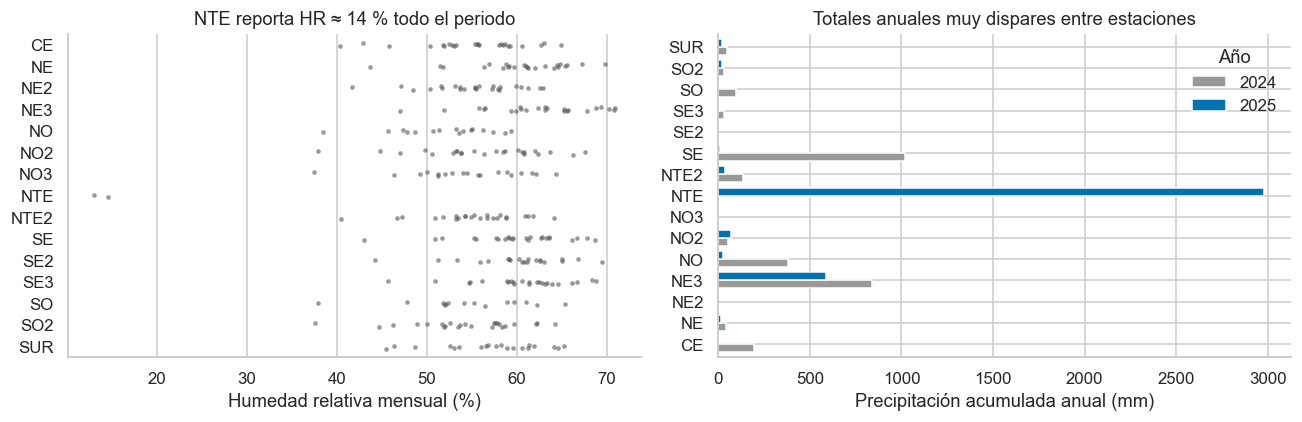

In [7]:
rh = datos.groupby("estacion")["RH"].agg(["count", "median", "min", "max"]).round(1)
llu = datos.pivot_table(index="estacion", columns="anio", values="RAINF", aggfunc="sum").round(0)
llu.columns = [f"lluvia_total_{c} (mm)" for c in llu.columns]
display(pd.concat([rh.add_prefix("RH_"), llu], axis=1))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.stripplot(data=datos, y="estacion", x="RH", ax=axs[0], size=3, color="#555", alpha=.6,
              order=sorted(datos.estacion.unique()))
axs[0].set_xlabel("Humedad relativa mensual (%)"); axs[0].set_ylabel("")
axs[0].set_title("NTE reporta HR ≈ 14 % todo el periodo")
llu_p = datos.pivot_table(index="estacion", columns="anio", values="RAINF", aggfunc="sum")
llu_p.plot.barh(ax=axs[1], color=["#999", "#0072B2"], width=.75)
axs[1].set_xlabel("Precipitación acumulada anual (mm)"); axs[1].set_ylabel(""); axs[1].legend(title="Año", frameon=False)
axs[1].set_title("Totales anuales muy dispares entre estaciones")
plt.tight_layout(); guardar("fig_calidad_meteorologia")

**Interpretación**

* **Patrón.** La HR de **NTE** es ≈ 14 % todos los meses (el resto de estaciones va de 38 a 71 %). La precipitación por estación es muy inconsistente: NE2, NO3 y SE2 reportan 0 mm en dos años, NTE reporta ≈ 2 980 mm en 2025 y 0 en 2024, y SE pasa de 1 020 mm (2024) a 12 mm (2025).
* **Relación con el objetivo.** La meteorología es el control del modelo. Con sensores así, la lluvia (y en menor medida la HR) por estación puede meter ruido o sesgo; por eso se depuran para explorar (`RH_dep`, `RAINF_dep`), con lo que quedan 306 y 259 estación-mes válidos.
* **Hallazgo / pregunta.** Temperatura y viento no muestran este problema. ¿Conviene reemplazar la lluvia por una serie regional única (mediana entre estaciones o fuente externa) en lugar de usarla por estación?

**Decisión operativa para el resto del notebook.** Se crean versiones depuradas `RH_dep` y `RAINF_dep` donde se pone en `NaN`:

* `RH` de **NTE** (constante ≈ 14 %, físicamente inverosímil en Monterrey).
* `RAINF` de **NE2, NO3 y SE2** (acumulado 0 mm en dos años) y de **NTE** (≈ 2 980 mm en 2025).

Las demás estaciones se conservan, pero los totales anuales siguen siendo muy dispares (p. ej. SE: 1 020 mm en 2024 y 12 mm en 2025), así que **la precipitación por estación debe tomarse con cautela**. Esta depuración es solo para explorar; se propone validarla con el equipo (o sustituir la lluvia por una serie regional externa) antes del modelado.

In [8]:
datos["RH_dep"] = datos["RH"].mask(datos.estacion.isin(["NTE"]))
datos["RAINF_dep"] = datos["RAINF"].mask(datos.estacion.isin(["NE2", "NO3", "SE2", "NTE"]))
MET_D = ["TOUT", "RH_dep", "RAINF_dep", "WSR"]
print("Estación-mes con RH_dep válida:", datos.RH_dep.notna().sum(), "| con RAINF_dep válida:", datos.RAINF_dep.notna().sum())

Estación-mes con RH_dep válida: 306 | con RAINF_dep válida: 259


---
# 4. Exploración descriptiva orientada al objetivo

## 4.1 Comportamiento de las variables principales

Se describen individualmente las variables que se usarán después: los tres contaminantes (respuesta), el NDVI mensual y la cobertura verde (explicativas) y la meteorología (control).

In [9]:
def resumen(df, cols):
    filas = []
    for c in cols:
        s = df[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        filas.append(dict(variable=c, n=len(s), faltantes_pct=100 * (1 - len(s) / len(df)),
                          media=s.mean(), mediana=s.median(), de=s.std(),
                          cv_pct=100 * s.std() / s.mean() if s.mean() else np.nan,
                          min=s.min(), q1=q1, q3=q3, max=s.max(), asimetria=s.skew(),
                          atipicos_iqr=int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())))
    return pd.DataFrame(filas).set_index("variable").round(2)

print("Contaminantes (estación-mes)")
t_cont = resumen(datos, CONT); display(t_cont)
print("Meteorología (depurada)")
t_met = resumen(datos, MET_D); display(t_met)
print("NDVI del entorno (estación-mes) por radio")
t_ndvi = resumen(datos, [f"ndvi_{r}" for r in RADIOS]); display(t_ndvi)
print("Cobertura estructural (15 estaciones) por radio")
est0 = datos.groupby("estacion")[[f"verde_{r}" for r in RADIOS] + [f"construido_{r}" for r in RADIOS]].first()
t_cob = resumen(est0, list(est0.columns)); display(t_cob)
for n, t in [("resumen_contaminantes", t_cont), ("resumen_meteorologia", t_met), ("resumen_ndvi", t_ndvi), ("resumen_cobertura", t_cob)]:
    guardar_tabla(t, n)

Contaminantes (estación-mes)


,n,faltantes_pct,media,mediana,de,cv_pct,min,q1,q3,max,asimetria,atipicos_iqr
variable,,,,,,,,,,,,
PM10,353,1.94,55.91,54.11,17.81,31.85,17.76,42.05,69.40,105.72,0.36,0
PM2.5,220,38.89,20.11,19.24,6.76,33.59,7.30,15.60,23.25,45.46,1.02,8
NO2,326,9.44,14.63,13.66,6.59,45.05,1.23,10.00,18.43,39.78,0.80,6


Meteorología (depurada)


,n,faltantes_pct,media,mediana,de,cv_pct,min,q1,q3,max,asimetria,atipicos_iqr
variable,,,,,,,,,,,,
TOUT,324,10.00,23.73,24.80,4.90,20.63,11.60,20.13,27.81,30.72,-0.63,0
RH_dep,306,15.00,57.17,58.04,6.47,11.32,37.48,53.24,61.43,70.91,-0.57,7
RAINF_dep,259,28.06,14.18,1.02,57.99,408.92,0.00,0.00,4.12,730.57,8.75,40
WSR,354,1.67,8.08,8.00,1.81,22.39,4.03,6.77,9.29,14.02,0.28,1


NDVI del entorno (estación-mes) por radio


,n,faltantes_pct,media,mediana,de,cv_pct,min,q1,q3,max,asimetria,atipicos_iqr
variable,,,,,,,,,,,,
ndvi_100,357,0.83,0.23,0.21,0.10,45.31,0.03,0.16,0.29,0.56,0.56,3
ndvi_300,355,1.39,0.20,0.19,0.07,36.87,0.09,0.16,0.23,0.57,1.97,16
ndvi_500,354,1.67,0.21,0.19,0.08,38.00,0.10,0.15,0.24,0.58,1.71,14
ndvi_1000,354,1.67,0.21,0.19,0.08,36.07,0.09,0.15,0.25,0.51,1.08,8
ndvi_2000,355,1.39,0.24,0.22,0.09,38.98,0.09,0.16,0.30,0.56,0.76,3


Cobertura estructural (15 estaciones) por radio


,n,faltantes_pct,media,mediana,de,cv_pct,min,q1,q3,max,asimetria,atipicos_iqr
variable,,,,,,,,,,,,
verde_100,15,0.0,1.61,0.00,6.23,387.30,0.00,0.00,0.00,24.13,3.87,1
verde_300,15,0.0,4.33,0.00,14.43,333.08,0.00,0.00,0.42,56.30,3.82,3
verde_500,15,0.0,7.14,1.15,16.77,234.96,0.00,0.27,6.36,66.32,3.58,1
verde_1000,15,0.0,9.41,2.85,16.35,173.75,0.01,0.97,12.51,64.83,3.13,1
verde_2000,15,0.0,16.66,11.38,18.16,108.98,0.56,4.39,22.79,72.28,2.22,1
construido_100,15,0.0,96.82,100.00,12.32,12.73,52.27,100.00,100.00,100.00,-3.87,1
construido_300,15,0.0,94.95,99.74,16.69,17.58,34.85,99.50,100.00,100.00,-3.82,3
construido_500,15,0.0,90.99,97.43,18.59,20.43,26.05,92.31,98.95,100.00,-3.46,1
construido_1000,15,0.0,87.18,93.97,19.64,22.53,23.22,85.43,97.97,99.55,-2.79,1


**Interpretación**

* **Patrón.** PM10 es la más simétrica (media 55.9, mediana 54.1 µg/m³, asimetría 0.36, sin atípicos). PM2.5 (media 20.1) y NO2 (media 14.6 ppb) tienen cola derecha (asimetría 1.0 y 0.8; 8 y 6 atípicos). NO2 es la más variable (CV 45 %, vs 32–34 % de PM). El NDVI(500 m) es bajo y asimétrico (media 0.21, mediana 0.19; asimetría 1.7), propio de un entorno urbano árido. La cobertura verde es extrema: **mediana de 1.2 % y media de 7.1 % a 500 m**, con 66 % en NE3; la mediana de superficie construida es 97 %.
* **Relación con el objetivo.** Casi todo el contraste de vegetación entre estaciones proviene de muy pocos sitios, y los contaminantes no son normales, lo que respalda usar correlaciones de rangos (Spearman) y desconfiar de ajustes lineales sensibles a atípicos.
* **Hallazgo / pregunta.** La lluvia depurada es muy asimétrica (mediana 1 mm, máximo 731 mm); si entra a un modelo conviene transformarla (p. ej. log(1+x)) o usarla como indicador de mes lluvioso.

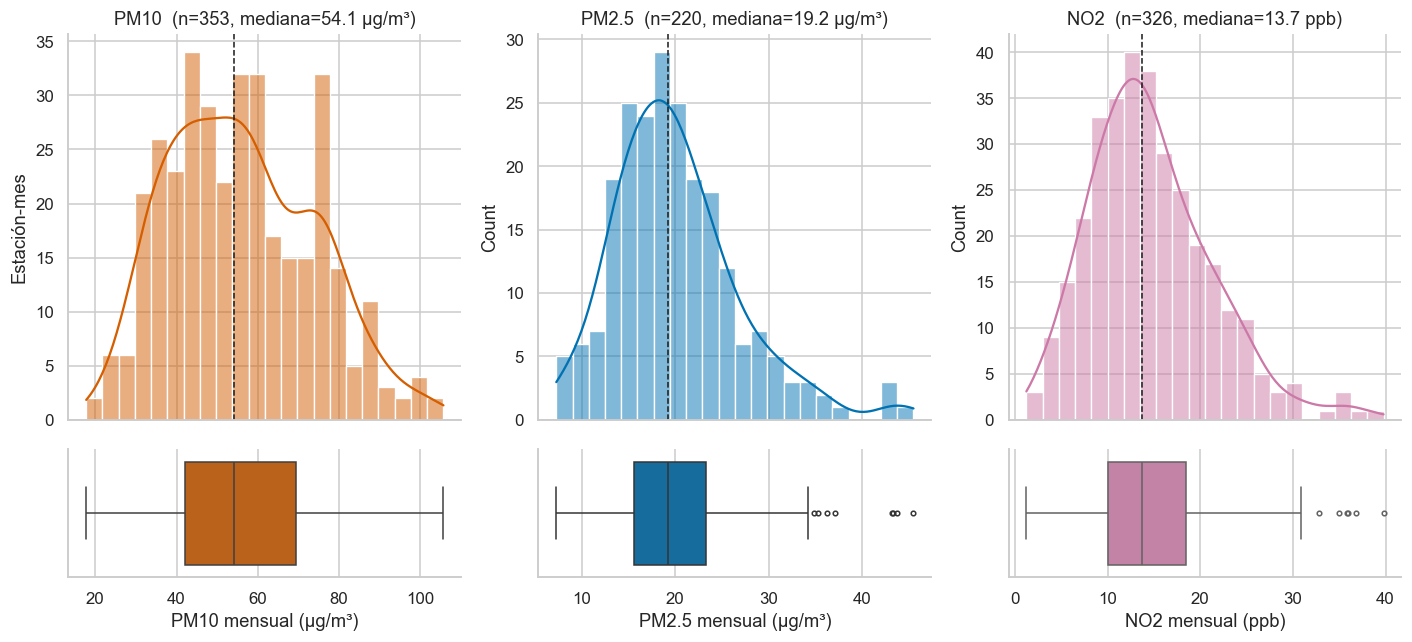

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(13, 6), gridspec_kw={"height_ratios": [3, 1]}, sharex="col")
for j, c in enumerate(CONT):
    s = datos[c].dropna()
    sns.histplot(s, bins=22, kde=True, color=COL[c], ax=axs[0, j], edgecolor="white")
    axs[0, j].axvline(s.median(), color="k", ls="--", lw=1); axs[0, j].set_xlabel("")
    axs[0, j].set_title(f"{c}  (n={len(s)}, mediana={s.median():.1f} {UNID[c]})")
    sns.boxplot(x=s, color=COL[c], ax=axs[1, j], fliersize=3)
    axs[1, j].set_xlabel(f"{c} mensual ({UNID[c]})")
axs[0, 0].set_ylabel("Estación-mes")
plt.tight_layout(); guardar("fig_4_1_distribucion_contaminantes")

**Interpretación.** Los tres contaminantes son unimodales; PM2.5 y NO2 muestran la cola de meses críticos (por ejemplo mayo de 2024 en PM2.5). Esto indica que unos pocos estación-mes concentran los valores altos, de modo que conviene revisar su influencia en los análisis posteriores en lugar de eliminarlos sin más.

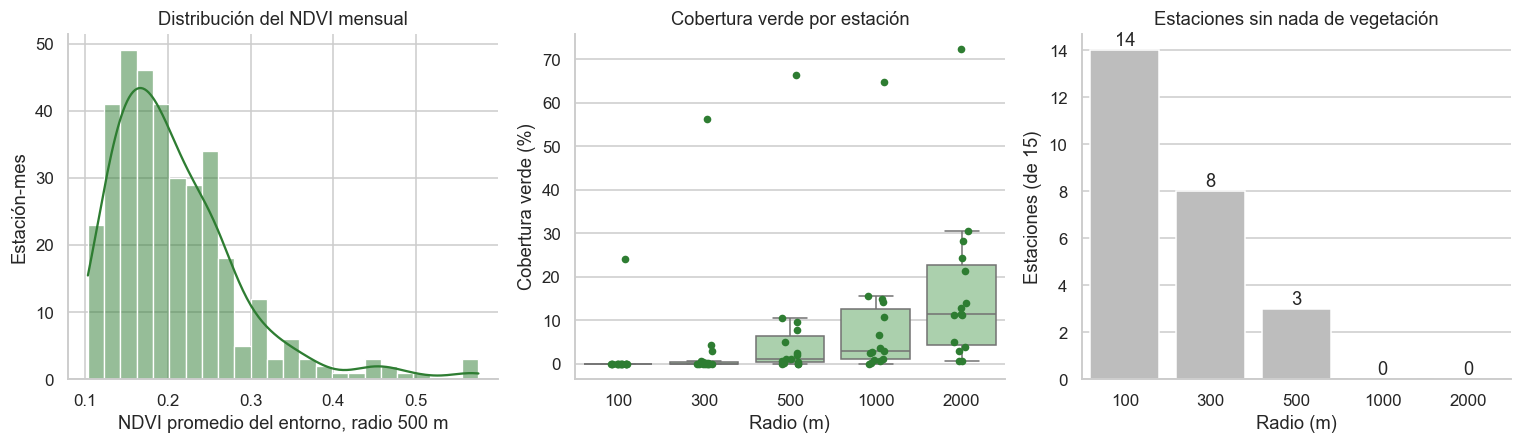

,radio,estaciones_con_0%
0,100,14
1,300,8
2,500,3
3,1000,0
4,2000,0


In [11]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
sns.histplot(datos[f"ndvi_{R0}"].dropna(), bins=24, kde=True, color=VERDE, ax=axs[0], edgecolor="white")
axs[0].set_xlabel(f"NDVI promedio del entorno, radio {R0} m"); axs[0].set_ylabel("Estación-mes"); axs[0].set_title("Distribución del NDVI mensual")

lv = est0[[f"verde_{r}" for r in RADIOS]].melt(var_name="radio", value_name="verde"); lv["radio"] = lv.radio.str.replace("verde_", "").astype(int)
sns.boxplot(data=lv, x="radio", y="verde", color="#A5D6A7", ax=axs[1], fliersize=0)
sns.stripplot(data=lv, x="radio", y="verde", color=VERDE, size=5, ax=axs[1])
axs[1].set_xlabel("Radio (m)"); axs[1].set_ylabel("Cobertura verde (%)"); axs[1].set_title("Cobertura verde por estación")

nz = pd.DataFrame({"radio": RADIOS, "estaciones_con_0%": [(est0[f"verde_{r}"] == 0).sum() for r in RADIOS]})
sns.barplot(data=nz, x="radio", y="estaciones_con_0%", color="#BDBDBD", ax=axs[2])
for i, v in enumerate(nz["estaciones_con_0%"]): axs[2].text(i, v + .2, int(v), ha="center")
axs[2].set_xlabel("Radio (m)"); axs[2].set_ylabel("Estaciones (de 15)"); axs[2].set_title("Estaciones sin nada de vegetación")
plt.tight_layout(); guardar("fig_4_1_distribucion_vegetacion")
display(nz)

**Interpretación**

* **Patrón.** A 100 m **14 de 15 estaciones tienen 0 % de vegetación**, a 300 m son 8, a 500 m son 3 y solo a 1 000 m todas tienen algo (mediana 2.9 %). NE3 es un caso aparte, con 24, 56, 66 y 65 % de verde en los cuatro radios.
* **Relación con el objetivo.** La variable explicativa espacial casi no varía a 100 m (empates masivos en cero) y a 300 m. El radio de 500 m, elegido como principal, es el primero con variación entre la mayoría de las estaciones, lo que respalda la decisión. NE3 será un punto de alta influencia en cualquier análisis entre estaciones.
* **Hallazgo / pregunta.** ¿Los resultados se sostienen al excluir NE3? Se evalúa en 4.4.

## 4.2 Comparación entre estaciones

Primero los contaminantes (¿cambian los niveles de un sitio a otro y cuánto de la variación total es "espacial"?) y luego el entorno de cada estación.

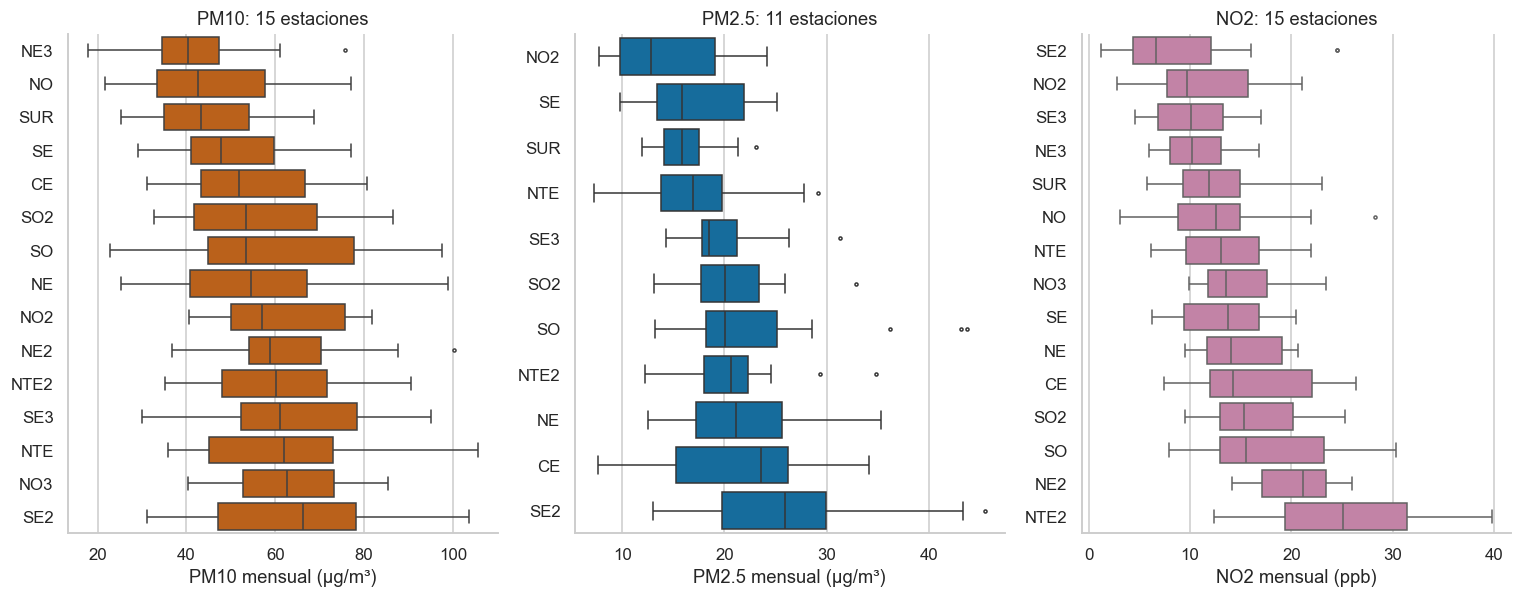

,estaciones,kruskal_H,p_valor,eta2_estacion,eta2_mes,media_min,est_min,media_max,est_max,razon_max_min
contaminante,,,,,,,,,,
PM10,15,59.756,0.0,0.169,0.705,41.565,NE3,65.182,SE2,1.568
PM2.5,11,48.643,0.0,0.234,0.437,14.157,NO2,25.854,SE2,1.826
NO2,15,118.808,0.0,0.417,0.392,8.925,SE2,25.511,NTE2,2.858


In [12]:
def eta2(df, y, g):
    d = df[[y, g]].dropna(); gm = d[y].mean()
    ssb = d.groupby(g)[y].apply(lambda s: len(s) * (s.mean() - gm) ** 2).sum()
    return ssb / ((d[y] - gm) ** 2).sum()

fig, axs = plt.subplots(1, 3, figsize=(14, 5.6))
for ax, c in zip(axs, CONT):
    d = datos.dropna(subset=[c]); orden = d.groupby("estacion")[c].median().sort_values().index
    sns.boxplot(data=d, y="estacion", x=c, order=orden, color=COL[c], ax=ax, fliersize=2, linewidth=1)
    ax.set_xlabel(f"{c} mensual ({UNID[c]})"); ax.set_ylabel("")
    ax.set_title(f"{c}: {d.estacion.nunique()} estaciones")
plt.tight_layout(); guardar("fig_4_2_contaminantes_por_estacion")

filas = []
for c in CONT:
    d = datos.dropna(subset=[c]); H, p = stats.kruskal(*[g[c].values for _, g in d.groupby("estacion")])
    med = d.groupby("estacion")[c].mean()
    filas.append(dict(contaminante=c, estaciones=d.estacion.nunique(), kruskal_H=H, p_valor=p,
                      eta2_estacion=eta2(d, c, "estacion"), eta2_mes=eta2(d.assign(ym=d.fecha_mes), c, "ym"),
                      media_min=med.min(), est_min=med.idxmin(), media_max=med.max(), est_max=med.idxmax(),
                      razon_max_min=med.max() / med.min()))
t_kw = pd.DataFrame(filas).set_index("contaminante"); display(t_kw.round(3)); guardar_tabla(t_kw.round(3), "kruskal_estaciones")

**Interpretación**

* **Patrón.** Las estaciones difieren de forma significativa en los tres contaminantes (Kruskal-Wallis, p < 0.001). NO2 es el que más cambia en el espacio: el promedio va de 8.9 ppb (SE2) a 25.5 ppb (NTE2), una razón de 2.9. En PM10 la razón es 1.6 (de 41.6 en NE3 a 65.2 en SE2) y en PM2.5 es 1.8 (de 14.2 en NO2 a 25.9 en SE2).
* **Cuánta variación es espacial.** La estación explica 42 % de la varianza de NO2, pero solo 23 % de PM2.5 y 17 % de PM10; el mes-año explica 71 % de PM10, 44 % de PM2.5 y 39 % de NO2. Es decir, PM10 y PM2.5 varían sobre todo **en el tiempo**, y NO2 tiene la mayor estructura espacial.
* **Relación con el objetivo.** Un gradiente de vegetación entre estaciones solo puede explicar la parte espacial. Se espera más señal en NO2 y poca en PM10; para PM, el control temporal (meteorología, mes, año) será indispensable.
* **Hallazgo / pregunta.** SE2 es la más alta en PM10 y PM2.5 pero la más baja en NO2; ¿se debe a fuentes de polvo/industriales locales más que a vegetación?

In [13]:
# Tabla integrada por estación: promedio de contaminantes + entorno (radio principal)
est = datos.groupby("estacion").agg(
    **{f"{c}_media": (c, "mean") for c in CONT},
    **{f"{c}_n": (c, "count") for c in CONT},
    verde_500=("verde_500", "first"), construido_500=("construido_500", "first"),
    ndvi_500_medio=("ndvi_500", "mean"), ndvi_500_sd=("ndvi_500", "std"))
for r in RADIOS: est[f"verde_{r}"] = datos.groupby("estacion")[f"verde_{r}"].first()
est.loc[~est.index.isin(PM25_EST), ["PM2.5_media"]] = np.nan
est = est.sort_values("verde_500", ascending=False)
display(est[["PM10_media", "PM2.5_media", "NO2_media", "verde_500", "construido_500", "ndvi_500_medio", "ndvi_500_sd"]].round(2))
guardar_tabla(est.round(3), "tabla_estaciones")

,PM10_media,PM2.5_media,NO2_media,verde_500,construido_500,ndvi_500_medio,ndvi_500_sd
estacion,,,,,,,
NE3,41.57,NaN,10.67,66.32,26.05,0.40,0.10
SE3,63.58,19.77,10.18,10.55,88.20,0.25,0.03
NO2,60.84,14.16,10.86,9.67,83.58,0.17,0.04
SE2,65.18,25.85,8.92,7.69,92.31,0.31,0.04
NO3,62.71,NaN,14.87,5.03,92.31,0.18,0.04
NTE,61.25,17.16,13.51,2.41,96.10,0.22,0.05
NTE2,60.58,20.47,25.51,1.91,97.43,0.22,0.03
SUR,44.53,16.28,12.43,1.15,98.85,0.21,0.02
SE,49.99,17.20,13.42,1.13,98.87,0.23,0.03


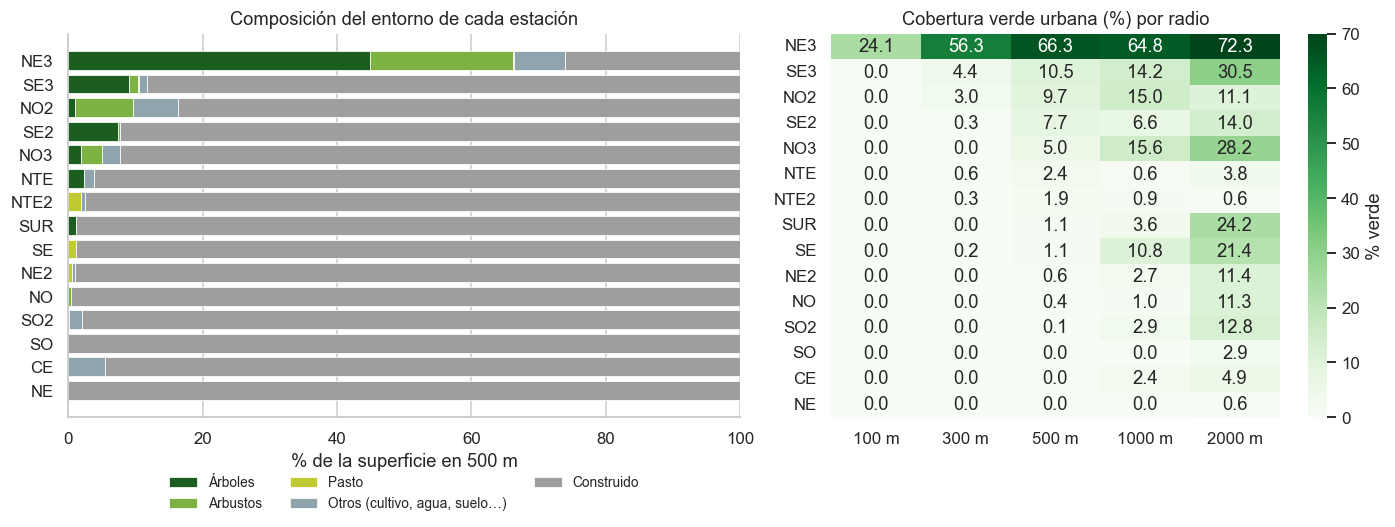

In [14]:
# Composición del entorno a 500 m y cobertura verde por radio
comp = cob[cob.radio_m == R0].set_index("estacion")
comp = comp.assign(otros=comp[["cultivos_pct", "vegetacion_inundada_pct", "suelo_desnudo_pct", "agua_pct", "nieve_hielo_pct"]].sum(axis=1))
comp = comp.sort_values("cobertura_verde_urbana_pct")
cols_c = [("arboles_pct", "Árboles", "#1B5E20"), ("arbustos_pct", "Arbustos", "#7CB342"), ("pasto_pct", "Pasto", "#C0CA33"),
          ("otros", "Otros (cultivo, agua, suelo…)", "#90A4AE"), ("construido_pct", "Construido", "#9E9E9E")]
fig, axs = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.2, 1]})
izq = np.zeros(len(comp))
for c, lab, col in cols_c:
    axs[0].barh(comp.index, comp[c], left=izq, color=col, label=lab, edgecolor="white", linewidth=.5); izq += comp[c].values
axs[0].set_xlabel(f"% de la superficie en {R0} m"); axs[0].set_xlim(0, 100)
axs[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.12), frameon=False, fontsize=9)
axs[0].set_title("Composición del entorno de cada estación")
hm = est[[f"verde_{r}" for r in RADIOS]].loc[comp.index[::-1]]; hm.columns = [f"{r} m" for r in RADIOS]
sns.heatmap(hm, annot=True, fmt=".1f", cmap="Greens", cbar_kws={"label": "% verde"}, ax=axs[1], vmin=0, vmax=70)
axs[1].set_ylabel(""); axs[1].set_title("Cobertura verde urbana (%) por radio")
plt.tight_layout(); guardar("fig_4_2_entorno_por_estacion")

**Interpretación**

* **Patrón.** El entorno de casi todas las estaciones es prácticamente concreto: **10 de 15 tienen menos de 2.5 % de verde a 500 m** y 12 más de 90 % de superficie construida. NE3 destaca (66 % verde, 45 % solo árboles); le siguen SE3 (10.5 %) y NO2 (9.7 %), donde predominan arbustos y pasto. La cobertura verde crece con el radio en la mayoría de los casos (SE y NO3 pasan de 1–5 % a 11–16 % a 1 000 m), señal de parques o lotes cercanos pero no inmediatos.
* **Relación con el objetivo.** Cobertura verde y construida son casi espejos (en la mayoría de sitios suman cerca de 100 %), así que separar el efecto de "más vegetación" del de "menos urbanización" será difícil con estos datos.
* **Hallazgo / pregunta.** El número efectivo de estaciones con contraste real de vegetación es pequeño (NE3, SE3, NO2, SE2, NO3).

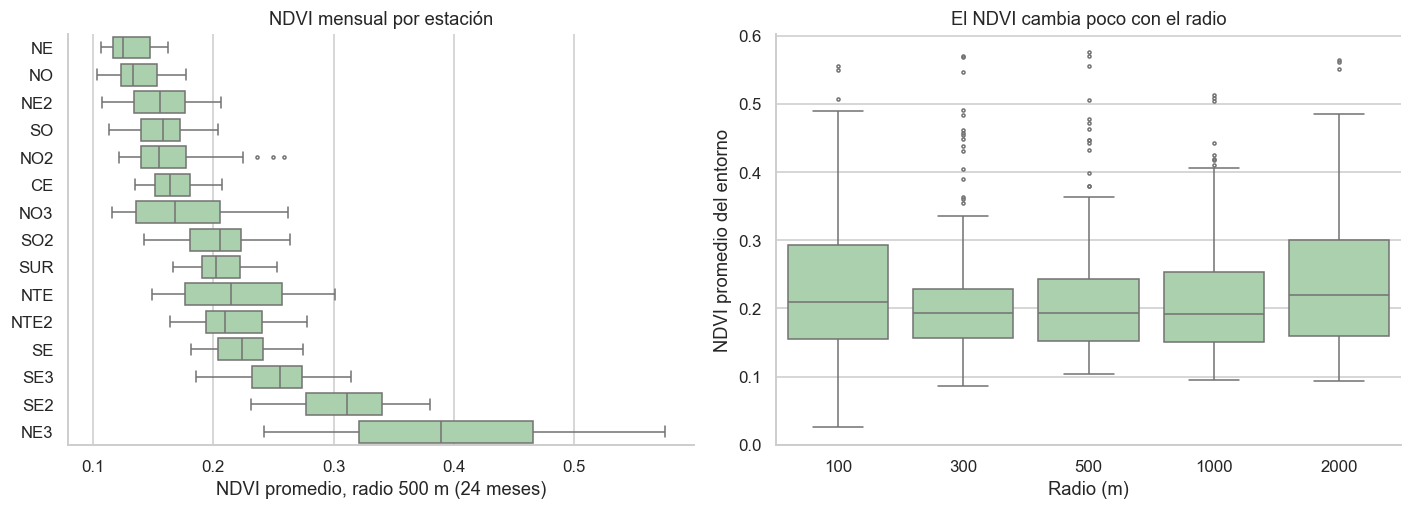

,proporción de la varianza
NDVI_500: eta² estación,0.746
NDVI_500: eta² mes,0.151


In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
orden = est.sort_values("ndvi_500_medio").index
sns.boxplot(data=datos, y="estacion", x="ndvi_500", order=orden, color="#A5D6A7", ax=axs[0], fliersize=2, linewidth=1)
axs[0].set_xlabel(f"NDVI promedio, radio {R0} m (24 meses)"); axs[0].set_ylabel(""); axs[0].set_title("NDVI mensual por estación")
v = datos[[f"ndvi_{r}" for r in RADIOS]].melt(var_name="radio", value_name="ndvi"); v["radio"] = v.radio.str.replace("ndvi_", "").astype(int)
sns.boxplot(data=v, x="radio", y="ndvi", color="#A5D6A7", ax=axs[1], fliersize=2)
axs[1].set_xlabel("Radio (m)"); axs[1].set_ylabel("NDVI promedio del entorno"); axs[1].set_title("El NDVI cambia poco con el radio")
plt.tight_layout(); guardar("fig_4_2_ndvi_por_estacion")
e2 = pd.Series({"NDVI_500: eta² estación": eta2(datos, "ndvi_500", "estacion"), "NDVI_500: eta² mes": eta2(datos, "ndvi_500", "fecha_mes")})
display(e2.round(3).to_frame("proporción de la varianza"))

**Interpretación.** El NDVI es mucho más una propiedad del **sitio** (74.6 % de su varianza es entre estaciones) que del tiempo (15 % por mes-año). Va de ≈ 0.13 (NE) a ≈ 0.40 (NE3), con SE2 (0.31) alto para solo 7.7 % de verde, lo que sugiere vegetación sana o pasto irrigado. El NDVI casi no cambia con el radio. Para el objetivo, esto significa que el NDVI también aporta información espacial y no solo temporal, y que su efecto temporal debe medirse **dentro** de cada estación.

## 4.3 Comparación entre periodos y temporadas

Temporadas definidas en la base: **seca** (ene–abr, nov–dic) y **húmeda** (may–oct).

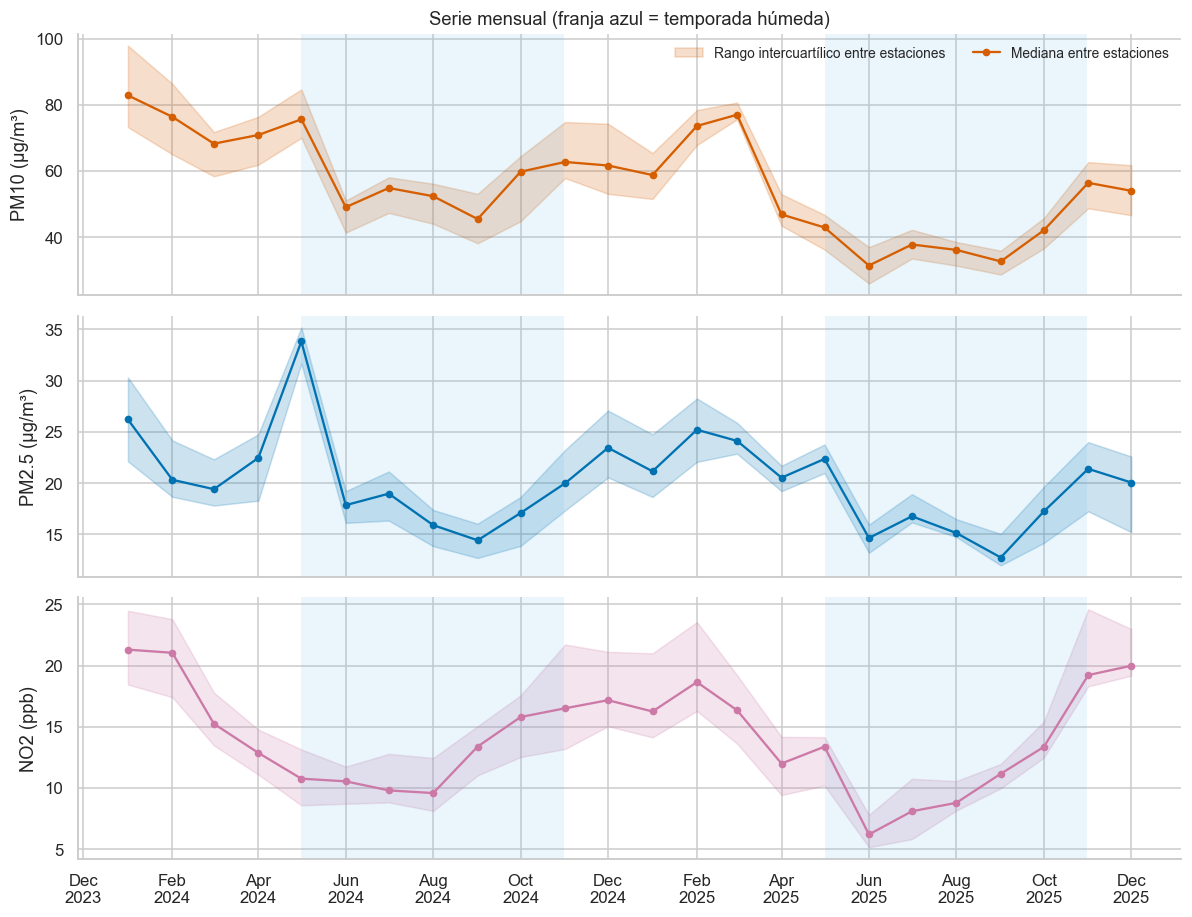

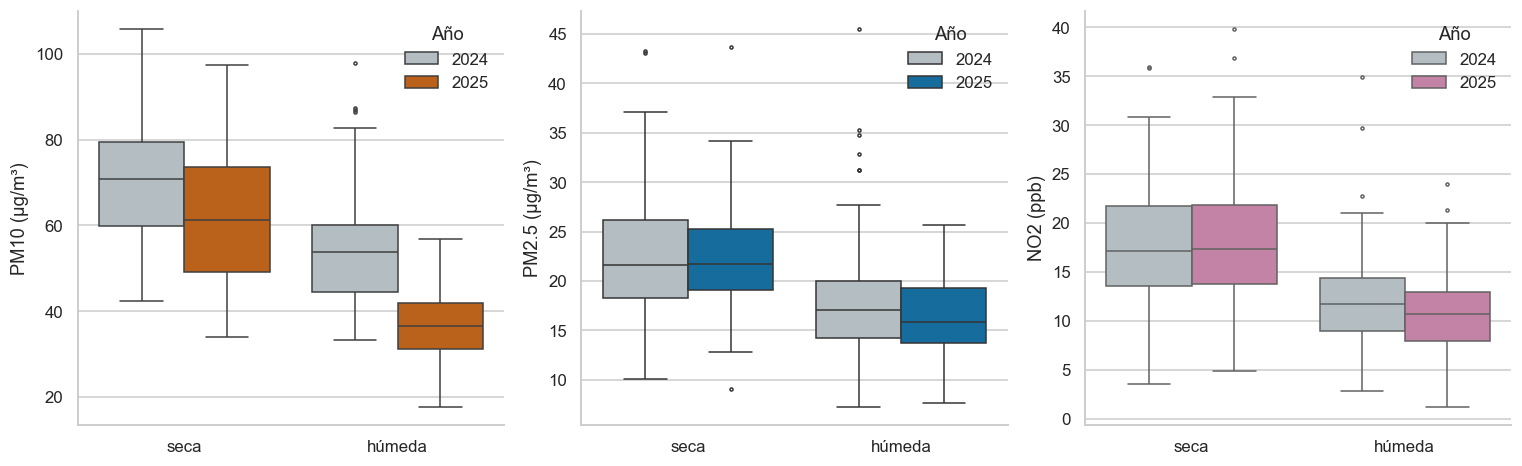

In [16]:
fig, axs = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
for ax, c in zip(axs, CONT):
    g = datos.groupby("fecha")[c]; med, q1, q3 = g.median(), g.quantile(.25), g.quantile(.75)
    ax.fill_between(med.index, q1, q3, color=COL[c], alpha=.2, label="Rango intercuartílico entre estaciones")
    ax.plot(med.index, med, color=COL[c], marker="o", ms=4, label="Mediana entre estaciones")
    for y in (2024, 2025):
        ax.axvspan(pd.Timestamp(y, 5, 1), pd.Timestamp(y, 10, 31), color=COL_T["húmeda"], alpha=.12, lw=0)
    ax.set_ylabel(f"{c} ({UNID[c]})")
axs[0].legend(loc="upper right", frameon=False, ncol=2, fontsize=9)
axs[0].set_title("Serie mensual (franja azul = temporada húmeda)")
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")); axs[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.tight_layout(); guardar("fig_4_3_series_mensuales")

fig, axs = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, c in zip(axs, CONT):
    sns.boxplot(data=datos.dropna(subset=[c]), x="temporada", y=c, hue="anio", order=["seca", "húmeda"], palette=["#B0BEC5", COL[c]], ax=ax, fliersize=2)
    ax.set_xlabel(""); ax.set_ylabel(f"{c} ({UNID[c]})"); ax.legend(title="Año", frameon=False)
plt.tight_layout(); guardar("fig_4_3_temporada_anio")

**Interpretación**

* **Patrón.** Hay un ciclo estacional claro: los tres contaminantes son más altos de noviembre a abril y mínimos en junio–septiembre. Además, **PM10 cae de forma marcada en 2025** (desde abril) y PM2.5 muestra un pico aislado en mayo de 2024.
* **Relación con el objetivo.** La estacionalidad es compartida por todas las estaciones, de modo que cualquier variable que también sea estacional (NDVI, temperatura, lluvia) se correlacionará con los contaminantes aunque no haya relación causal.
* **Hallazgo / pregunta.** ¿La baja de PM10 en 2025 es real (menos polvo, lluvias) o un cambio de instrumento o calibración? PM2.5 y NO2 no bajan, lo que hace dudar.

In [17]:
def comp_pareada(df, y, factor, a, b):
    p = df.groupby(["estacion", factor])[y].mean().unstack()[[a, b]].dropna()
    w = stats.wilcoxon(p[a], p[b])
    return dict(variable=y, comparacion=f"{b} vs {a}", n_estaciones=len(p), media_a=p[a].mean(), media_b=p[b].mean(),
                dif_pct=100 * (p[b].mean() / p[a].mean() - 1), estaciones_que_suben=int((p[b] > p[a]).sum()), p_wilcoxon=w.pvalue)

vars_t = CONT + ["ndvi_500", "TOUT", "WSR"]
res = [comp_pareada(datos, v, "temporada", "seca", "húmeda") for v in vars_t] + \
      [comp_pareada(datos, v, "anio", 2024, 2025) for v in vars_t]
t_per = pd.DataFrame(res).round(3); display(t_per); guardar_tabla(t_per, "comparacion_periodos")

,variable,comparacion,n_estaciones,media_a,media_b,dif_pct,estaciones_que_suben,p_wilcoxon
0,PM10,húmeda vs seca,15,65.901,45.926,-30.309,0,0.000
1,PM2.5,húmeda vs seca,11,22.293,17.298,-22.407,1,0.002
2,NO2,húmeda vs seca,15,17.761,11.438,-35.596,0,0.000
3,ndvi_500,húmeda vs seca,15,0.210,0.207,-1.615,4,0.454
4,TOUT,húmeda vs seca,15,19.802,27.558,39.165,15,0.000
5,WSR,húmeda vs seca,15,7.490,8.635,15.283,15,0.000
6,PM10,2025 vs 2024,15,62.666,49.392,-21.183,0,0.000
7,PM2.5,2025 vs 2024,11,20.092,19.723,-1.838,5,0.831
8,NO2,2025 vs 2024,15,14.815,14.590,-1.525,5,0.561
9,ndvi_500,2025 vs 2024,15,0.220,0.197,-10.416,0,0.000


**Interpretación**

* **Temporadas.** En la húmeda, PM10 baja 30 %, PM2.5 22 % y NO2 36 %; la baja se da en todas las estaciones en PM10 y NO2 y en 10 de 11 en PM2.5. Coincide con temperaturas 39 % más altas y viento 15 % más fuerte, que favorecen la dispersión. **El NDVI no cambia entre temporadas** (−1.6 %, p = 0.45).
* **Años.** PM10 baja 21 % de 2024 a 2025 en las 15 estaciones (p < 0.001), mientras PM2.5 (−1.8 %) y NO2 (−1.5 %) no cambian. El NDVI baja 10 % en 2025 también en las 15.
* **Relación con el objetivo.** Hay un cambio "de año" común que afecta a la vez a PM10 y NDVI. Si no se controla, producirá una correlación positiva falsa entre ambos. Se requerirá un control de año/mes (efectos fijos de tiempo).
* **Hallazgo / pregunta.** La clasificación seca/húmeda es útil para los contaminantes pero no para el NDVI, como se ve a continuación.

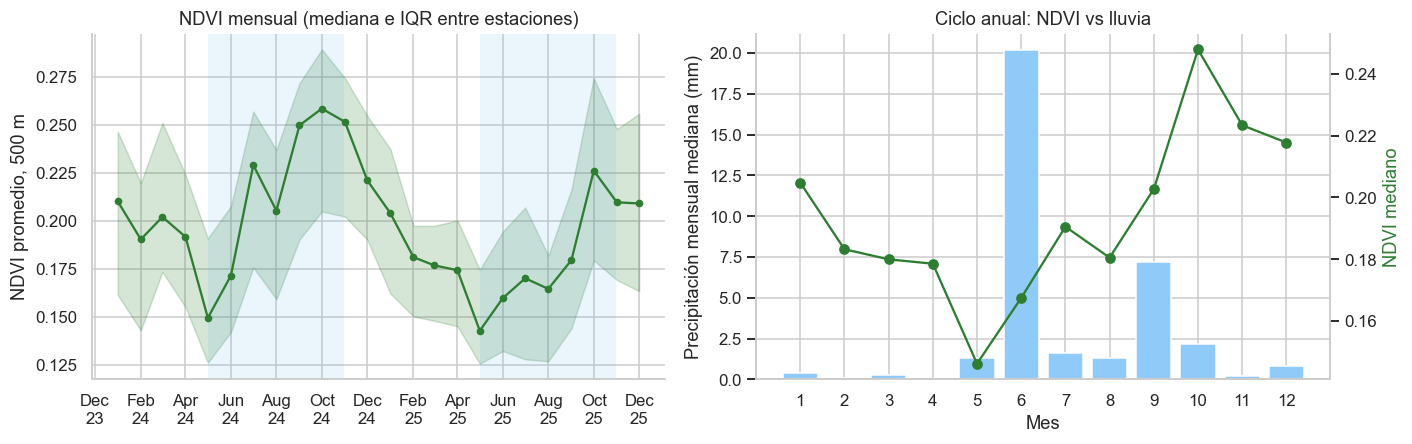

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
g = datos.groupby("fecha")["ndvi_500"]; med, q1, q3 = g.median(), g.quantile(.25), g.quantile(.75)
axs[0].fill_between(med.index, q1, q3, color=VERDE, alpha=.2); axs[0].plot(med.index, med, color=VERDE, marker="o", ms=4)
for y in (2024, 2025): axs[0].axvspan(pd.Timestamp(y, 5, 1), pd.Timestamp(y, 10, 31), color=COL_T["húmeda"], alpha=.12, lw=0)
axs[0].set_ylabel(f"NDVI promedio, {R0} m"); axs[0].set_title("NDVI mensual (mediana e IQR entre estaciones)")
axs[0].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%y")); axs[0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))

pt = datos.groupby("mes")[["ndvi_500", "RAINF_dep"]].median()
ax2 = axs[1]; ax2.bar(pt.index, pt["RAINF_dep"], color="#90CAF9", label="Lluvia mediana (mm)")
ax2.set_ylabel("Precipitación mensual mediana (mm)"); ax2.set_xlabel("Mes")
ax3 = ax2.twinx(); ax3.plot(pt.index, pt["ndvi_500"], color=VERDE, marker="o"); ax3.set_ylabel("NDVI mediano", color=VERDE); ax3.grid(False)
ax3.spines["right"].set_visible(True); ax2.set_xticks(range(1, 13)); axs[1].set_title("Ciclo anual: NDVI vs lluvia")
plt.tight_layout(); guardar("fig_4_3_ndvi_temporal")

**Interpretación.** El NDVI toca fondo en **mayo** (≈ 0.15) y alcanza su máximo en **octubre** (≈ 0.25), con un desfase respecto a la lluvia (pico mediano en junio). Es decir, la vegetación reverdece semanas después de las lluvias, y por eso el promedio de la temporada húmeda (mayo–octubre) se confunde con meses de NDVI mínimo. Para el objetivo: un posible efecto de la vegetación debería buscarse con el NDVI del mismo mes o rezagado y no con la etiqueta de temporada; y la lluvia debe evaluarse con rezago frente al NDVI.

### Tipo de día y hora (base horaria)

La base horaria disponible (`base_unida1.csv`) todavía contiene códigos centinela (`999`, `-9999`). Aquí solo se aplican reglas mínimas (centinelas y valores negativos de contaminantes → `NaN`); la limpieza completa del equipo es la que prevalece para el modelado. Para no ponderar más a las estaciones con más datos, se promedia primero por estación y luego entre estaciones (PM2.5: solo las 11 estaciones seleccionadas).

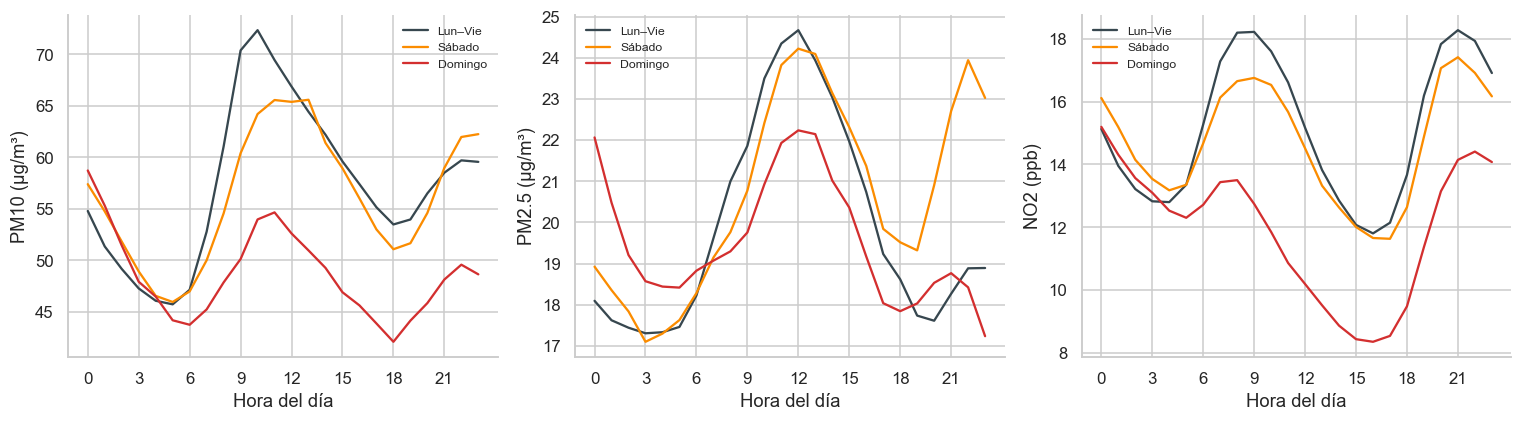

tipo_dia,Domingo,Lun–Vie,Sábado,Dom/Lab (%)
PM10,48.65,57.29,56.17,-15.08
PM2.5,19.58,19.97,20.68,-1.97
NO2,11.94,15.14,14.70,-21.13


Filas horarias con centinelas eliminados -> NaN. Horas válidas PM10/PM2.5/NO2: {'PM10': 251814, 'PM2.5': 164425, 'NO2': 239015}


In [19]:
h = hor.copy()
for c in ["PM10", "PM2.5"]: h.loc[h[c] >= 999, c] = np.nan
for c in h.columns.difference(["date", "estacion"]): h.loc[h[c] <= -9000, c] = np.nan
for c in CONT: h.loc[h[c] < 0, c] = np.nan
h.loc[(h.estacion.isin(PM25_EST) == False), "PM2.5"] = np.nan
h["hora"] = h.date.dt.hour
h["tipo_dia"] = np.select([h.date.dt.dayofweek < 5, h.date.dt.dayofweek == 5], ["Lun–Vie", "Sábado"], "Domingo")
ciclo = h.groupby(["estacion", "tipo_dia", "hora"])[CONT].mean().groupby(["tipo_dia", "hora"]).mean().reset_index()

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
pal = {"Lun–Vie": "#37474F", "Sábado": "#FB8C00", "Domingo": "#D32F2F"}
for ax, c in zip(axs, CONT):
    sns.lineplot(data=ciclo, x="hora", y=c, hue="tipo_dia", palette=pal, ax=ax, hue_order=list(pal))
    ax.set_xlabel("Hora del día"); ax.set_ylabel(f"{c} ({UNID[c]})"); ax.set_xticks(range(0, 24, 3)); ax.legend(title="", frameon=False, fontsize=8)
plt.tight_layout(); guardar("fig_4_3_ciclo_horario")

dd = h.groupby(["estacion", "tipo_dia"])[CONT].mean().groupby("tipo_dia").mean().T
dd["Dom/Lab (%)"] = 100 * (dd["Domingo"] / dd["Lun–Vie"] - 1)
display(dd.round(2)); guardar_tabla(dd.round(2), "tipo_dia")
print("Filas horarias con centinelas eliminados -> NaN. Horas válidas PM10/PM2.5/NO2:", h[CONT].notna().sum().to_dict())

**Interpretación**

* **Patrón.** NO2 tiene dos picos (≈ 8–9 h y 20–21 h) y PM10 un pico matutino (≈ 10 h): el perfil típico del tráfico. Los domingos NO2 baja 21 % y PM10 15 % respecto a lunes–viernes, mientras PM2.5 casi no cambia (−2 %).
* **Relación con el objetivo.** NO2 depende mucho de la actividad vehicular, que difiere entre estaciones; esto puede confundir su relación con la vegetación. PM2.5 parece menos ligado al tráfico local.
* **Hallazgo / pregunta.** ¿Existe información de tráfico o cercanía a vialidades por estación para controlar este factor?

## 4.4 Relaciones entre variables

Hay **dos preguntas distintas** y requieren dos miradas:

* **Espacial** (entre estaciones): ¿las estaciones con más vegetación a su alrededor tienen, en promedio, menos contaminante? Solo hay 15 puntos (11 en PM2.5).
* **Temporal** (dentro de cada estación): cuando el NDVI sube o baja, ¿se mueve el contaminante? Aquí hay hasta 360 estación-mes, pero el NDVI y los contaminantes comparten estacionalidad.

### 4.4.1 Relación espacial: cobertura del entorno vs contaminante promedio de la estación

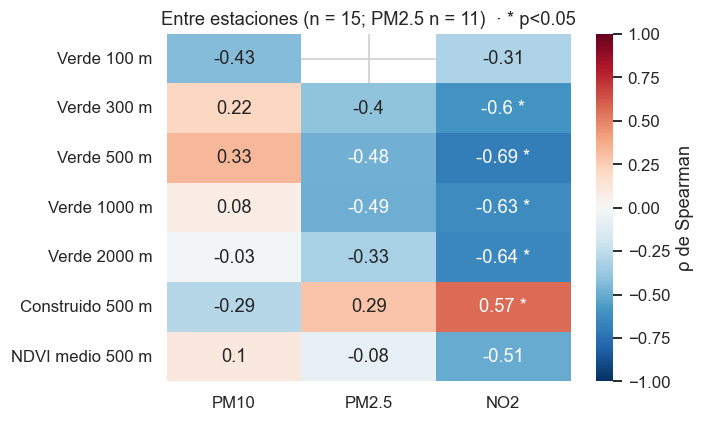

,predictor,contaminante,n,rho,p,rho_sin_NE3
0,Verde 100 m,PM10,15,-0.433,0.107,NaN
1,Verde 100 m,PM2.5,11,NaN,NaN,NaN
2,Verde 100 m,NO2,15,-0.309,0.262,NaN
3,Verde 300 m,PM10,15,0.217,0.437,0.528
4,Verde 300 m,PM2.5,11,-0.400,0.222,-0.400
5,Verde 300 m,NO2,15,-0.600,0.018,-0.523
6,Verde 500 m,PM10,15,0.330,0.230,0.638
7,Verde 500 m,PM2.5,11,-0.477,0.138,-0.477
8,Verde 500 m,NO2,15,-0.688,0.005,-0.634
9,Verde 1000 m,PM10,15,0.075,0.791,0.323


In [20]:
est_s = datos.groupby("estacion")[CONT].mean()
est_s.loc[~est_s.index.isin(PM25_EST), "PM2.5"] = np.nan
est_s = est_s.join(est[[f"verde_{r}" for r in RADIOS] + ["construido_500", "ndvi_500_medio"]])
preds = {f"verde_{r}": f"Verde {r} m" for r in RADIOS} | {"construido_500": "Construido 500 m", "ndvi_500_medio": "NDVI medio 500 m"}

filas = []
for p, lab in preds.items():
    for c in CONT:
        d = est_s[[p, c]].dropna(); rho, pv = stats.spearmanr(d[p], d[c])
        d2 = d.drop(index="NE3", errors="ignore"); rho2 = stats.spearmanr(d2[p], d2[c])[0]
        filas.append(dict(predictor=lab, contaminante=c, n=len(d), rho=rho, p=pv, rho_sin_NE3=rho2))
t_esp = pd.DataFrame(filas)
piv = t_esp.pivot(index="predictor", columns="contaminante", values="rho").loc[list(preds.values()), CONT]
pvs = t_esp.pivot(index="predictor", columns="contaminante", values="p").loc[list(preds.values()), CONT]
anot = piv.round(2).astype(str) + np.where(pvs < .05, " *", "")
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(piv, annot=anot, fmt="", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar_kws={"label": "ρ de Spearman"}, ax=ax)
ax.set_title("Entre estaciones (n = 15; PM2.5 n = 11)  · * p<0.05"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); guardar("fig_4_4_spearman_espacial")
display(t_esp.round(3)); guardar_tabla(t_esp.round(3), "spearman_espacial")

**Interpretación**

* **Patrón.** Con **NO2** hay asociación negativa consistente en los tres radios con variación: ρ = −0.60 (300 m), **−0.69 (500 m, p = 0.005)** y −0.63 (1 000 m). Se mantiene sin NE3 (−0.63 a 500 m). Con **PM2.5** también es negativa pero más débil y no significativa (−0.40 a −0.49; n = 11). Con **PM10** es nula o *positiva* (+0.33; +0.64 sin NE3): las estaciones algo más verdes no tienen menos PM10. A 100 m PM2.5 no puede calcularse (todas las estaciones con cero verde). La superficie construida refleja lo mismo en sentido inverso (NO2: +0.57).
* **Relación con el objetivo.** Es la primera evidencia directa: más vegetación alrededor se asocia con menos NO2 entre estaciones, pero no con menos PM10.
* **Hallazgo / pregunta.** Con 15 puntos, pocos sitios con vegetación y verde ≈ opuesto de construido, esto es consistente con vegetación pero también con "zonas menos urbanas/menos tráfico". Además, los p-valores no se ajustan por múltiples comparaciones (18 pruebas). ¿Qué estaciones están realmente lejos de vialidades?

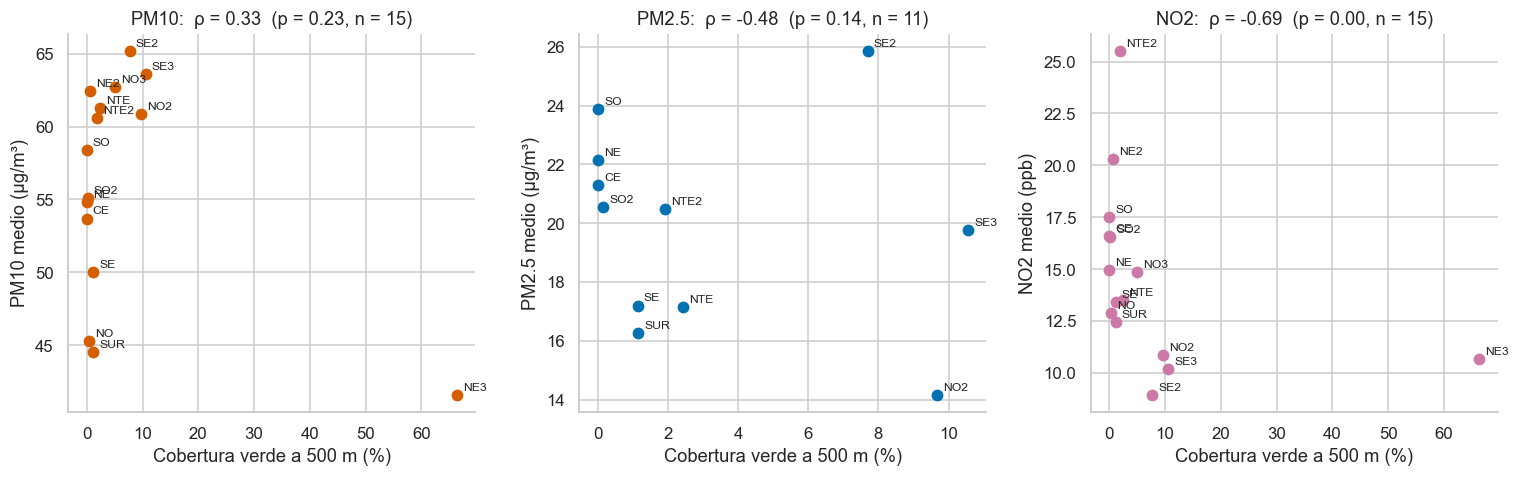

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, c in zip(axs, CONT):
    d = est_s[[f"verde_{R0}", c]].dropna()
    ax.scatter(d[f"verde_{R0}"], d[c], color=COL[c], s=45, zorder=3)
    for k, r in d.iterrows(): ax.annotate(k, (r[f"verde_{R0}"], r[c]), xytext=(4, 3), textcoords="offset points", fontsize=8)
    rho, pv = stats.spearmanr(d[f"verde_{R0}"], d[c])
    ax.set_title(f"{c}:  ρ = {rho:.2f}  (p = {pv:.2f}, n = {len(d)})"); ax.set_xlabel(f"Cobertura verde a {R0} m (%)"); ax.set_ylabel(f"{c} medio ({UNID[c]})")
plt.tight_layout(); guardar("fig_4_4_dispersion_espacial")

### 4.4.2 Relación temporal: NDVI mensual vs contaminante dentro de cada estación

Se reportan tres correlaciones de Spearman por radio y contaminante, de menos a más exigente:

1. **Global**: todos los estación-mes juntos (mezcla diferencias entre sitios y entre meses).
2. **Intra-estación**: a cada valor se le resta el promedio de su estación (quita diferencias fijas entre sitios).
3. **Sin efectos comunes de tiempo** (`ef2`): además se resta el promedio de cada mes-año entre estaciones, es decir, se quitan estacionalidad y cambios de año que afectan a todas las estaciones por igual (equivale a los efectos fijos de estación y mes que se usarían en la regresión).

,radio,contaminante,n,rho_global,rho_intra_estacion,p_intra,rho_ef2,p_ef2,mediana_rho_por_estacion,estaciones_rho_neg,estaciones
0,100,PM10,350,-0.198,0.096,0.073,0.008,0.885,0.083,4,15
1,100,PM2.5,217,-0.144,-0.106,0.121,0.005,0.943,-0.071,7,11
2,100,NO2,323,-0.011,0.312,0.000,0.014,0.808,0.329,2,15
3,300,PM10,348,-0.079,0.093,0.082,0.065,0.225,0.130,5,15
4,300,PM2.5,215,-0.037,-0.208,0.002,-0.118,0.086,-0.173,8,11
5,300,NO2,321,-0.088,0.302,0.000,0.051,0.366,0.338,2,15
6,500,PM10,347,0.014,0.075,0.162,0.068,0.203,0.113,5,15
7,500,PM2.5,214,-0.050,-0.242,0.000,-0.158,0.021,-0.214,8,11
8,500,NO2,320,-0.090,0.303,0.000,0.035,0.528,0.376,2,15
9,1000,PM10,347,0.012,0.090,0.094,0.073,0.172,0.077,4,15


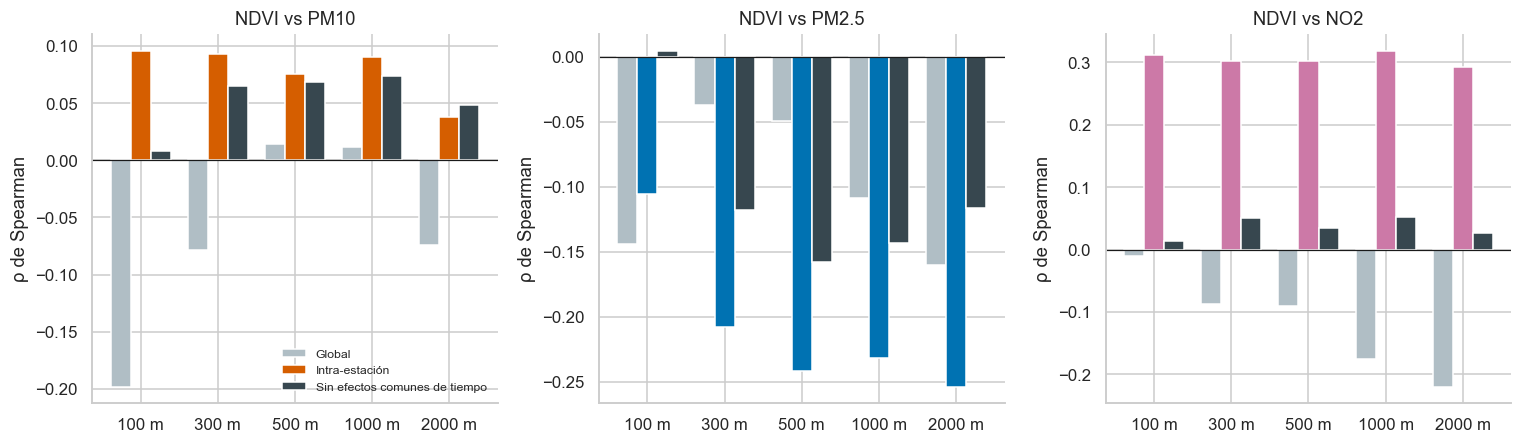

In [22]:
def dem(df, col, by): return df[col] - df.groupby(by)[col].transform("mean")

filas = []
for r in RADIOS:
    x = f"ndvi_{r}"
    for c in CONT:
        d = datos[["estacion", "fecha_mes", x, c]].dropna()
        rho_p, p_p = stats.spearmanr(d[x], d[c])
        d = d.assign(xw=dem(d, x, "estacion"), yw=dem(d, c, "estacion"))
        rho_w, p_w = stats.spearmanr(d.xw, d.yw)
        d = d.assign(xr=d.xw - d.groupby("fecha_mes")["xw"].transform("mean"), yr=d.yw - d.groupby("fecha_mes")["yw"].transform("mean"))
        rho_s, p_s = stats.spearmanr(d.xr, d.yr)
        por_est = pd.Series({k: stats.spearmanr(g[x], g[c])[0] for k, g in d.groupby("estacion") if len(g) >= 10})
        filas.append(dict(radio=r, contaminante=c, n=len(d), rho_global=rho_p, rho_intra_estacion=rho_w, p_intra=p_w,
                          rho_ef2=rho_s, p_ef2=p_s, mediana_rho_por_estacion=por_est.median(),
                          estaciones_rho_neg=int((por_est < 0).sum()), estaciones=len(por_est)))
t_tem = pd.DataFrame(filas); display(t_tem.round(3)); guardar_tabla(t_tem.round(3), "spearman_temporal")

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharey=False)
for ax, c in zip(axs, CONT):
    pv_ = t_tem.pivot(index="radio", columns="contaminante", values="rho_global")[c]
    pw_ = t_tem.pivot(index="radio", columns="contaminante", values="rho_intra_estacion")[c]
    ps_ = t_tem.pivot(index="radio", columns="contaminante", values="rho_ef2")[c]
    xs = np.arange(len(RADIOS)); w = .26
    ax.bar(xs - w, pv_, w, color="#B0BEC5", label="Global"); ax.bar(xs, pw_, w, color=COL[c], label="Intra-estación"); ax.bar(xs + w, ps_, w, color="#37474F", label="Sin efectos comunes de tiempo")
    ax.axhline(0, color="k", lw=.8); ax.set_xticks(xs, [f"{r} m" for r in RADIOS]); ax.set_ylabel("ρ de Spearman"); ax.set_title(f"NDVI vs {c}")
axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); guardar("fig_4_4_spearman_temporal")

**Interpretación**

* **Patrón.** El NDVI no se relaciona con los contaminantes cuando se mira junto (|ρ| ≤ 0.20). Dentro de cada estación aparece NO2 positivo (ρ ≈ +0.30, mediana por estación ≈ +0.33 a +0.41) y PM2.5 negativo (≈ −0.21 a −0.24), pero al quitar los efectos comunes de tiempo, **el NO2 y el PM10 caen a ≈ 0 (|ρ| ≤ 0.09, no significativos) y solo PM2.5 conserva una asociación negativa débil** (≈ −0.14 a −0.16 a 500 y 1 000 m; p = 0.02–0.04). La señal de PM2.5 aparece en 8 de 11 estaciones.
* **Relación con el objetivo.** Los valores intra-estación de NO2 son estacionalidad pura (el NDVI es alto en otoño, cuando sube el NO2). Esto muestra que el efecto temporal del NDVI **no es identificable sin controlar mes/año**.
* **Hallazgo / pregunta.** ¿Un efecto pequeño en PM2.5 sobrevive al añadir temperatura, viento y lluvia? Es la pregunta natural para la regresión con efectos fijos.

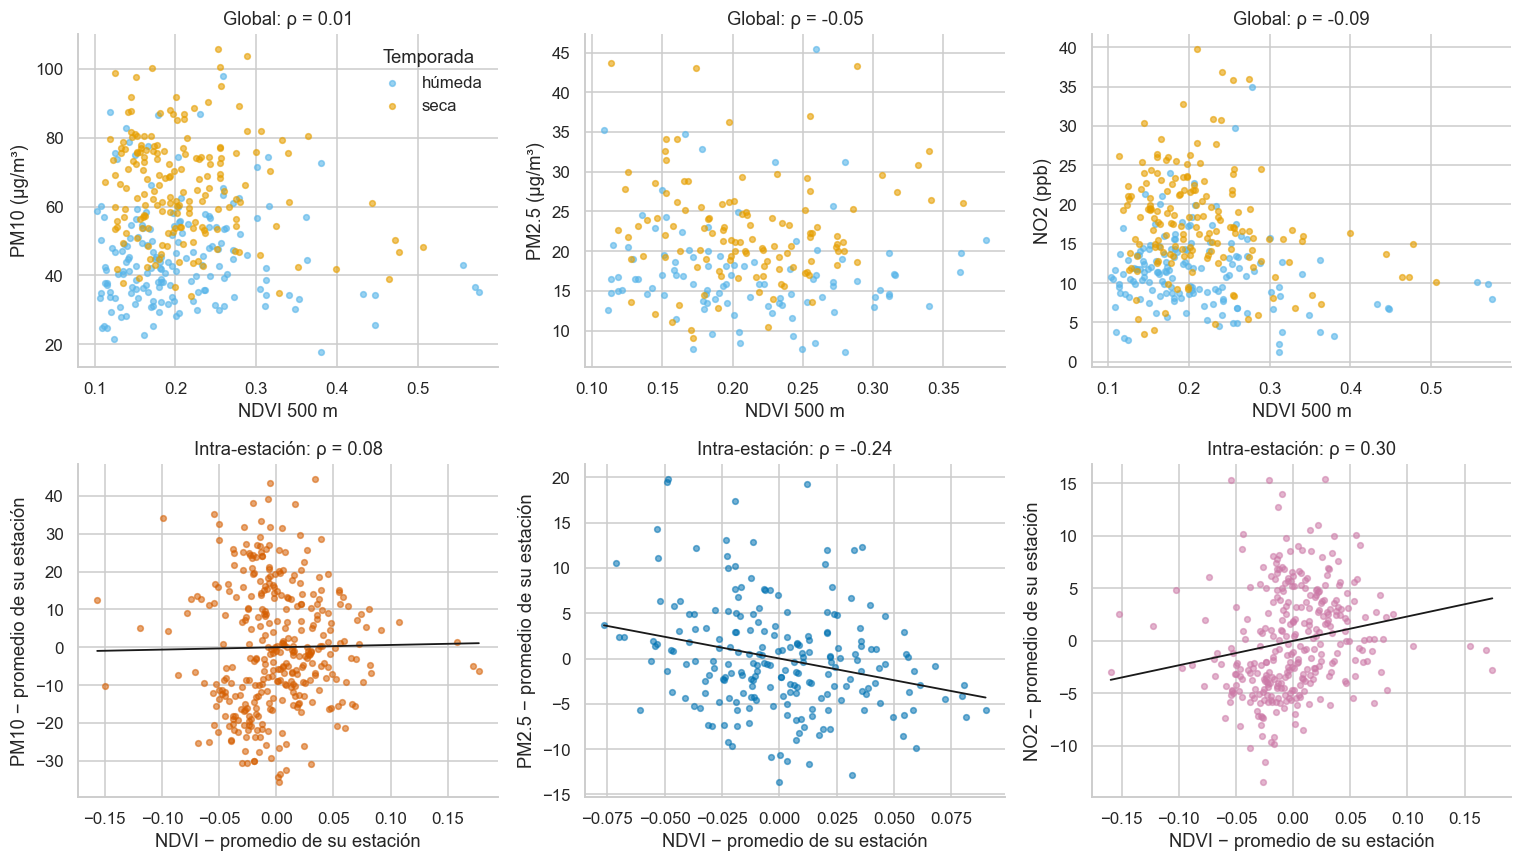

In [23]:
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
x = f"ndvi_{R0}"
for j, c in enumerate(CONT):
    d = datos[["estacion", "mes", "temporada", x, c]].dropna()
    for t, g in d.groupby("temporada"): axs[0, j].scatter(g[x], g[c], s=14, alpha=.6, color=COL_T["húmeda" if t == "húmeda" else "seca"], label=t)
    axs[0, j].set_xlabel(f"NDVI {R0} m"); axs[0, j].set_ylabel(f"{c} ({UNID[c]})"); axs[0, j].set_title(f"Global: ρ = {stats.spearmanr(d[x], d[c])[0]:.2f}")
    xw, yw = dem(d, x, "estacion"), dem(d, c, "estacion")
    axs[1, j].scatter(xw, yw, s=14, alpha=.55, color=COL[c]); b = np.polyfit(xw, yw, 1); xx = np.linspace(xw.min(), xw.max(), 50)
    axs[1, j].plot(xx, np.polyval(b, xx), color="k", lw=1.2)
    axs[1, j].set_xlabel(f"NDVI − promedio de su estación"); axs[1, j].set_ylabel(f"{c} − promedio de su estación")
    axs[1, j].set_title(f"Intra-estación: ρ = {stats.spearmanr(xw, yw)[0]:.2f}")
axs[0, 0].legend(title="Temporada", frameon=False)
plt.tight_layout(); guardar("fig_4_4_dispersion_temporal")

### 4.4.3 Meteorología, contaminantes y NDVI: matriz de correlaciones y colinealidad

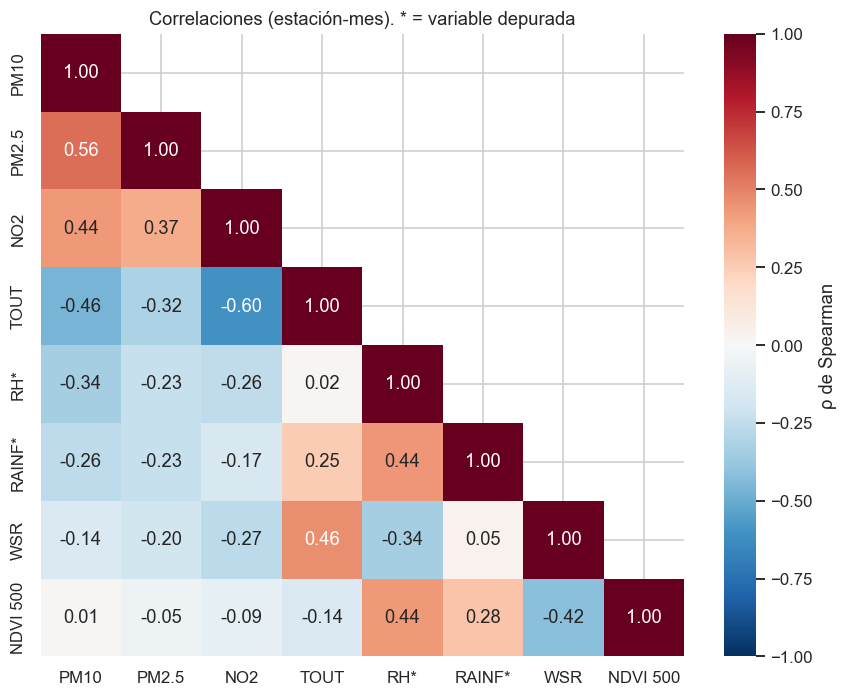

Casos completos para VIF: 220


,VIF
TOUT,1.36
RH_dep,1.46
RAINF_dep,1.15
WSR,1.61
ndvi_500,1.50


In [24]:
vv = CONT + ["TOUT", "RH_dep", "RAINF_dep", "WSR", f"ndvi_{R0}"]
etq = {"RH_dep": "RH*", "RAINF_dep": "RAINF*", f"ndvi_{R0}": f"NDVI {R0}"}
corr = datos[vv].corr(method="spearman").rename(index=etq, columns=etq)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "ρ de Spearman"})
ax.set_title("Correlaciones (estación-mes). * = variable depurada")
plt.tight_layout(); guardar("fig_4_4_matriz_correlacion"); guardar_tabla(corr.round(3), "matriz_correlacion")

# Colinealidad entre las posibles explicativas del modelo (casos completos)
X = datos[["TOUT", "RH_dep", "RAINF_dep", "WSR", f"ndvi_{R0}"]].dropna()
Xc = (X - X.mean()) / X.std(); Xc.insert(0, "const", 1.0)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X.columns, name="VIF")
print(f"Casos completos para VIF: {len(X)}"); display(vif.round(2).to_frame())

**Interpretación**

* **Patrón.** La temperatura es la variable más asociada a los contaminantes (NO2 −0.60, PM10 −0.46, PM2.5 −0.32); la HR (−0.23 a −0.34) y el viento (−0.14 a −0.27) también son negativas. PM10–PM2.5 se correlacionan 0.56 y NO2 con ambos 0.37–0.44. El NDVI casi no se correlaciona con los contaminantes (0.01, −0.05, −0.09), pero sí con HR (+0.44), lluvia (+0.28) y viento (−0.42). Los VIF entre las explicativas son ≤ 1.6 (n = 220 casos completos).
* **Relación con el objetivo.** La meteorología explica más variación mensual que la vegetación y está ligada al NDVI, así que omitirla sesgaría cualquier efecto atribuido a la vegetación. Como los VIF son bajos, pueden incluirse todas juntas sin colinealidad grave.
* **Hallazgo / pregunta.** El análisis multivariado (PCA) puede resumir PM y meteorología; el viento y la temperatura son las candidatas a ejes principales.

### 4.4.4 ¿Miden lo mismo el NDVI y la cobertura de Dynamic World?

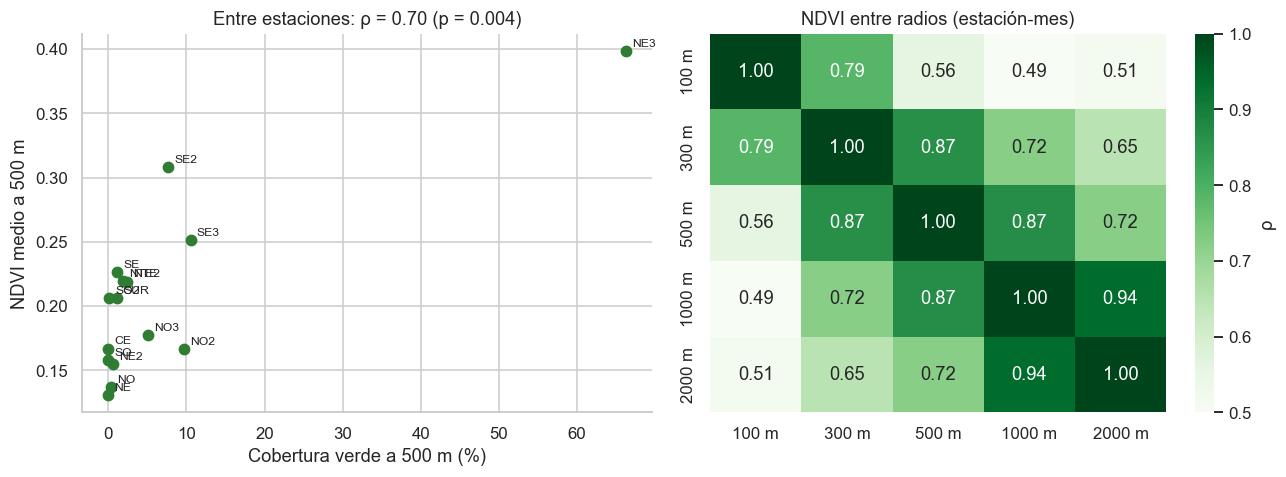

ρ(verde_r, NDVI medio 500 m): {100: np.float64(0.43), 300: np.float64(0.71), 500: np.float64(0.7), 1000: np.float64(0.53), 2000: np.float64(0.55)}


In [25]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
d = est[["verde_500", "ndvi_500_medio"]].dropna()
axs[0].scatter(d.verde_500, d.ndvi_500_medio, color=VERDE, s=45)
for k, r in d.iterrows(): axs[0].annotate(k, (r.verde_500, r.ndvi_500_medio), xytext=(4, 3), textcoords="offset points", fontsize=8)
rho, pv = stats.spearmanr(d.verde_500, d.ndvi_500_medio)
axs[0].set_xlabel("Cobertura verde a 500 m (%)"); axs[0].set_ylabel("NDVI medio a 500 m"); axs[0].set_title(f"Entre estaciones: ρ = {rho:.2f} (p < 0.001)" if pv < .001 else f"Entre estaciones: ρ = {rho:.2f} (p = {pv:.3f})")
cr = datos[[f"ndvi_{r}" for r in RADIOS]].corr(method="spearman"); cr.index = cr.columns = [f"{r} m" for r in RADIOS]
sns.heatmap(cr, annot=True, fmt=".2f", cmap="Greens", vmin=.5, vmax=1, ax=axs[1], cbar_kws={"label": "ρ"}); axs[1].set_title("NDVI entre radios (estación-mes)")
plt.tight_layout(); guardar("fig_4_4_ndvi_vs_cobertura")
rv = {r: stats.spearmanr(est[f"verde_{r}"], est["ndvi_500_medio"])[0] for r in RADIOS}
print("ρ(verde_r, NDVI medio 500 m):", {k: round(v, 2) for k, v in rv.items()})

**Interpretación.** El NDVI medio por estación y la cobertura verde de Dynamic World se asocian de forma moderada-alta (ρ = 0.70 a 500 m; 0.71 a 300 m; 0.53 a 1 000 m): miden cosas relacionadas pero no idénticas (por ejemplo SE2 tiene NDVI alto con poco verde clasificado). Se justifica conservar ambos indicadores: uno para el contraste espacial y otro para la variación temporal.

### Cierre del punto 4: síntesis de hallazgos descriptivos y cómo orientan el análisis

**Principales hallazgos descriptivos**

1. **La vegetación del entorno es escasa y está muy concentrada**: 10 de 15 estaciones tienen menos de 2.5 % de verde a 500 m; NE3 (66 %) es el único sitio realmente verde.
2. **La mayor parte de la variación de PM10 y PM2.5 es temporal** (mes-año explica 71 % y 44 %), mientras que **NO2 tiene la mayor estructura espacial** (42 % entre estaciones).
3. **Entre estaciones**, más verde se asocia con menos NO2 (ρ ≈ −0.6 a −0.7) y, más débilmente, con menos PM2.5; para PM10 no hay relación.
4. **En el tiempo**, la relación NDVI–contaminante desaparece o es muy débil una vez que se controla la estacionalidad y el año; solo PM2.5 conserva una asociación negativa pequeña.
5. **Hay confusores importantes**: temperatura y viento (más asociados a los contaminantes que la vegetación), un descenso común de PM10 y NDVI en 2025 y un NDVI que sigue la lluvia con rezago.

**Cómo orientan el análisis posterior:** (i) para el análisis espacial se usará Spearman con el radio de 500 m, reportando sensibilidad sin NE3 y con 300 y 1 000 m; (ii) para el temporal, la regresión incluirá efectos fijos de estación y mes-año (o año y estacionalidad), más temperatura, humedad, viento y lluvia depurada; (iii) el PCA se aplicará a contaminantes y meteorología con estación y temporada como agrupación; (iv) se priorizará NO2 y PM2.5, con PM10 como contraste.

---
# 5. Síntesis

**1. ¿Qué han descubierto hasta ahora acerca del problema?**
El entorno de las estaciones del SIMA es casi totalmente construido (mediana de 97 % a 500 m) y la vegetación se concentra en unos pocos sitios (NE3, SE3, NO2). Los contaminantes tienen un fuerte ciclo estacional (más altos de noviembre a abril y 22–36 % menores en la temporada húmeda) y la meteorología, sobre todo la temperatura, se asocia más con ellos que la vegetación.

**2. ¿Qué resultados descriptivos se relacionan directamente con el objetivo?**
(a) Entre estaciones, la cobertura verde se asocia negativamente con NO2 (ρ = −0.69 a 500 m, p = 0.005; −0.63 sin NE3) y débilmente con PM2.5 (ρ ≈ −0.48, n = 11, no significativo), pero no con PM10. (b) En el tiempo, el NDVI mensual no muestra relación con NO2 ni PM10 una vez controlados estacionalidad y año; con PM2.5 queda una asociación negativa pequeña (ρ ≈ −0.15, p < 0.05). (c) NO2 es el contaminante con más variación espacial (42 %), así que es el más apto para detectar un efecto de la vegetación del entorno.

**3. ¿Qué limitaciones o problemas encontraron en los datos?**
* PM2.5: 39 % de faltantes y solo 11 estaciones; NE3, la más verde, no tiene PM2.5.
* Solo 15 estaciones y muy poca variación de vegetación (14 de 15 con 0 % a 100 m); NE3 es un punto de alta influencia.
* Cobertura verde y construida son casi complementarias: se confunden vegetación y baja urbanización/tráfico.
* Sensores meteorológicos dudosos: HR de NTE ≈ 14 %, lluvia con totales inverosímiles o nulos en 4 estaciones y muy dispares en las demás.
* Cambios comunes de año: PM10 −21 % y NDVI −10 % en 2025 (posible efecto instrumental o ambiental), que pueden crear correlaciones falsas.
* La cobertura de Dynamic World es fija en el periodo; NDVI faltante o con poca cobertura en julio de 2024 (nubes); la base horaria usada aún contiene códigos centinela.

**4. ¿Qué análisis falta realizar?**
Correlaciones de Spearman formales con el radio principal y sensibilidad (sin NE3, otros radios, NDVI de vegetación), regresión lineal múltiple del NDVI sobre cada contaminante con efectos fijos de estación y mes-año y controles meteorológicos (errores agrupados por estación), el PCA exploratorio de contaminantes y meteorología, el análisis de rezagos NDVI–lluvia y los diagnósticos de residuales. Además, verificar la caída de PM10 en 2025 y resolver el tratamiento de la lluvia.

**5. ¿Qué camino seguirá el equipo para responder el objetivo?**
Se seguirá la ruta propuesta: (1) Spearman estación-nivel para el contraste espacial de la cobertura verde (500 m, con sensibilidad); (2) regresión múltiple con efectos fijos para el efecto temporal del NDVI, controlando meteorología; (3) PCA para describir patrones conjuntos de contaminantes y meteorología por estación y temporada. NO2 y PM2.5 serán las respuestas principales, y PM10 un contraste. Las conclusiones se plantearán como asociaciones, no causalidad.

**6. ¿Qué nuevas preguntas surgieron durante la exploración?**
* ¿La asociación verde–NO2 refleja vegetación o menor tráfico/cercanía a vialidades? ¿Hay datos de tráfico o distancia a vías?
* ¿Cambia algo en PM10 y NO2 al restringir a las 11 estaciones de PM2.5?
* ¿La baja de PM10 en 2025 es real o instrumental?
* ¿Conviene sustituir la lluvia por estación por una serie regional externa?
* ¿Tiene el NDVI un efecto rezagado (reverdece semanas después de la lluvia) sobre los contaminantes?
* ¿Por qué SE2 es alta en PM pero baja en NO2 (fuentes locales)?